# Track 2 Advanced: Portfolio Selection at 20 Stocks with a Budget-Keeping QAOA

**Qiskit Fall Fest 2026, IIIT-Delhi, Track 2 (Quantum Optimization)**
Team: **Wave Riders** | Level reached: **Advanced**

**Goal.** Choose exactly **K = 10 of n = 20** stocks with at most **2 stocks per sector** (5 contiguous sectors of
4 stocks, the README's own example rule), minimizing risk-adjusted cost. QAOA starts from a Dicke state and uses
an XY ring mixer, so the budget holds by construction; the sector rule is a soft penalty whose strength comes from
the data alone. We then test what breaks at scale (training, circuit size after routing, noise) and check every
answer against exact brute force.

**Headline (full-mode run; every number below is from this notebook's outputs).**

1. **The budget is exact by construction.** The Dicke start and the XY ring mixer keep exactly K stocks, so no
   budget penalty is needed. Verified: the Pauli expansion equals the direct cost on all 184,756 budget-feasible
   portfolios (max error 1.95e-14); the n = 20 Dicke circuit has overlap 1.000000000000 with the ideal Dicke state;
   the Qiskit circuit matches the training simulator at n = 12 and n = 16 (overlap 1.000000000000, all probability
   on K-stock portfolios); and the n = 20 pick is re-scored from `mu` and `sigma` regenerated with the README code.
2. **The sector rule is soft.** It is a penalty, so samples can break it. At n = 20 (seed 2026, p = 4) 49.0% of
   the QAOA probability is on portfolios that obey it; the median over 8 seeds is 51.8%, 46.9% and 49.2% at
   n = 12, 16 and 20. Post-selection discards the rest.
3. **Gain over the fair baseline** (uniform sampling over the 216 / 1,296 / 7,776 cap-feasible portfolios at
   n = 12 / 16 / 20). The **pre-committed recipe** (CVaR alpha = 0.2, p = 4, data-bound penalty), median over 8
   seeds: **22.7x, 2.4x and 0.50x**. Only n = 12 passes the "solved well" bar (median at least 10x); at n = 20 the
   typical trained state finds the optimum less often than the classical cap-feasible sampler. A **tuned recipe T**
   (alpha = 0.01, p = 6, chosen by looking at seed 2026 only) on the **held-out** seeds 2027-2033: **3.6x, 13.1x and
   30.2x**. It passes at n = 16 and 20 but not at n = 12, where it is worse than the pre-committed recipe on all 7
   held-out seeds. Recipe T is a sensitivity result, not the verdict: we added this test after seeing the
   pre-committed results on all eight seeds; recipe T's settings were taken from the seed-2026 sweeps only.
4. **Classical methods solve these instances with far less work.** At n = 20, greedy + 1-swap finds the optimum
   with 556 cost evaluations and simulated annealing with 2,000 steps finds it in 17 of 20 runs. QAOA's p = 4
   training alone took 131 objective calls (63 grid values + 68 exact value-and-gradient) over all 184,756
   portfolios, and then needs 8,096 shots
   for 99% confidence of seeing the optimum.
5. **Hardware.** For one p = 1 layer at n = 20 on `FakeSherbrooke`, Dicke preparation is 2,042 of the 3,163
   routed two-qubit gates on a heavy-hex path (65%). The estimated success probability is about 2e-11
   (2.75e-11 with free layout, 1.82e-11 on the path), so no hardware run is feasible. A line SWAP network for the
   pair terms adds 192 gates before routing but needs no routing on a line: the whole circuit drops from 3,163 to
   2,833 routed gates on the heavy-hex path (-10.4%) and from 3,110 to 3,030 with free layout (-2.6%). In a noisy n = 12 simulation (8,192 shots) the cap-feasible, top-10 and optimum rates among valid
   shots are indistinguishable from pure noise within 95% Wilson intervals; the valid-shot rate without DD
   (21.5%, interval 20.6%-22.4%) is even slightly below the pure-noise 22.6%.
6. **Limits.** No QPU was run. Pauli twirling is not simulated. The dynamical-decoupling result is a simulator
   artifact (Aer's noise model has no coherent crosstalk for DD to suppress).

**Deviation notes.** (1) No real QPU run: hardware evidence comes from a fake IBM backend (transpile counts and a
noisy simulation). (2) Pauli twirling is a runtime option on real QPUs and is not simulated here; we simulate
dynamical decoupling and post-selection only. (3) The sector rule, the penalty (now data-only) and the headline
random baseline were changed after review; Sections 1 and 6 say what changed and why.

**Tested with** Python 3.14, numpy 2.5.4, scipy 1.18.1, matplotlib 3.11.2, pandas 3.0.6, jinja2 3.1.6, qiskit 2.5.2,
qiskit-aer 0.17.2, qiskit-ibm-runtime 0.50.0. The Qiskit stack is pinned because the transpiled gate counts in
Section 5 depend on the transpiler version. `DataFrame.map` needs pandas >= 2.1;
`DataFrame.style` needs jinja2.

**Run time.** About an hour on a laptop CPU. Setting the environment variable `ADV_FAST=1` runs a smoke-test
version with small knobs in a few minutes; its numbers are not results.


## 0. Setup

Installs only if a package is missing, prints the versions in use and the run-size knobs.

In [1]:
import importlib.util, os, sys
FAST = os.environ.get("ADV_FAST") == "1"
print("FAST mode:", FAST, "(smoke test only: these numbers are NOT the reported results)" if FAST else "(full settings)")
_REQUIRED = ["numpy", "scipy", "matplotlib", "pandas", "jinja2", "qiskit", "qiskit_aer", "qiskit_ibm_runtime"]
_missing = [m for m in _REQUIRED if importlib.util.find_spec(m) is None]
if _missing:
    print("installing missing packages:", _missing)
    %pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" "numpy>=2.0" "scipy>=1.13" "matplotlib>=3.8" "pandas>=2.1" "jinja2>=3.1"

import warnings
import numpy, scipy, matplotlib, pandas, jinja2, qiskit, qiskit_aer, qiskit_ibm_runtime
from scipy.sparse import SparseEfficiencyWarning
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)   # only filter: scipy sparse-format efficiency hints
print("python", sys.version.split()[0])
for _m in (numpy, scipy, matplotlib, pandas, jinja2, qiskit, qiskit_aer, qiskit_ibm_runtime):
    print(f"{_m.__name__:20s} {_m.__version__}")
assert tuple(int(v) for v in pandas.__version__.split(".")[:2]) >= (2, 1), "DataFrame.map needs pandas >= 2.1"
pandas.set_option("display.max_columns", None)          # show every column of the wide verdict tables
pandas.set_option("display.width", 250)
# (jinja2 is needed by pandas DataFrame.style, used for two tables)

# Heavy knobs (FAST shrinks them for a smoke test; the reported results use the full settings)
PMAX = 3 if FAST else 6                                   # deepest QAOA layer trained at n = 20
MAXITER = 15 if FAST else 40                              # L-BFGS-B iterations per layer
P_V = min(4, PMAX)                                        # depth of the verdict runs (fixed at 4 before any run)
P_LAMBDA = 2 if FAST else 4                               # depth of the lambda sweep
ALPHAS = (0.01, 0.05, 0.2)                                # CVaR tail fractions (0.2 = main run)
GV_DRAWS = 20 if FAST else 200                            # random angle draws per (n, p) in the gradient check
NOISE_SHOTS = 512 if FAST else 8192                       # shots per noisy simulation at n = 12
SEEDS_V = [2026, 2027] if FAST else list(range(2026, 2034))   # instances per size in the verdict
# Held-out tuned recipe T (fixed before its run; chosen by looking at seed 2026 only, so 2026 is excluded)
ALPHA_T = 0.01                                            # CVaR tail fraction of recipe T
P_T = 3 if FAST else 6                                    # recipe T depth (trained and evaluated at p = P_T)
SEEDS_T = [2027, 2028] if FAST else list(range(2027, 2034))   # held-out seeds for recipe T
print(dict(PMAX=PMAX, MAXITER=MAXITER, P_V=P_V, P_LAMBDA=P_LAMBDA, ALPHAS=ALPHAS, GV_DRAWS=GV_DRAWS,
           NOISE_SHOTS=NOISE_SHOTS, SEEDS_V=SEEDS_V, ALPHA_T=ALPHA_T, P_T=P_T, SEEDS_T=SEEDS_T))

FAST mode: False (full settings)


python 3.14.6
numpy                2.5.4
scipy                1.18.1
matplotlib           3.11.2
pandas               3.0.6
jinja2               3.1.6
qiskit               2.5.2
qiskit_aer           0.17.2
qiskit_ibm_runtime   0.50.0
{'PMAX': 6, 'MAXITER': 40, 'P_V': 4, 'P_LAMBDA': 4, 'ALPHAS': (0.01, 0.05, 0.2), 'GV_DRAWS': 200, 'NOISE_SHOTS': 8192, 'SEEDS_V': [2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033], 'ALPHA_T': 0.01, 'P_T': 6, 'SEEDS_T': [2027, 2028, 2029, 2030, 2031, 2032, 2033]}


In [2]:
# ---- inlined module: advanced_core.py ----
"""Core numerics for the Track 2 Advanced notebook (n stocks, pick K, sector cap)."""
from itertools import combinations
from math import comb

import numpy as np


# ---------------------------------------------------------------- problem data
def make_instance(n=20, K=10, q=0.5, seed=2026, n_sectors=4, cap=3):
    """README generator, unchanged; sectors are contiguous blocks (not drawn from rng)."""
    if n % n_sectors:
        raise ValueError("n must be divisible by n_sectors (contiguous equal-size sectors)")
    rng = np.random.default_rng(seed)
    mu = rng.uniform(0.05, 0.25, n)
    A = rng.normal(0, 0.1, (n, n))
    sigma = A @ A.T
    sector = np.arange(n) // (n // n_sectors)
    return dict(n=n, K=K, q=q, mu=mu, sigma=sigma, sector=sector,
                n_sectors=n_sectors, cap=cap)


def feasible_states(n, K):
    """Sorted integer encodings (bit i = stock i) of every weight-K bitstring."""
    combos = np.array(list(combinations(range(n), K)), dtype=np.int64)
    ints = (np.int64(1) << combos).sum(axis=1)
    ints.sort()
    return ints


def bits_matrix(ints, n):
    return ((ints[:, None] >> np.arange(n)) & 1).astype(np.int8)


# ---------------------------------------------------------------- cost pieces
def base_cost(X, inst):
    """q x^T Sigma x - mu^T x for each row of the 0/1 matrix X."""
    Xf = X.astype(float)
    return inst["q"] * np.einsum("bi,ij,bj->b", Xf, inst["sigma"], Xf) - Xf @ inst["mu"]


def sector_excess(X, inst):
    """sum_s max(0, n_s - cap)^2 for each row of X."""
    out = np.zeros(X.shape[0])
    for s in range(inst["n_sectors"]):
        c = X[:, inst["sector"] == s].sum(axis=1)
        out += np.maximum(0, c - inst["cap"]) ** 2
    return out


def choose_lambda_s(base, excess, margin=1.05):
    """Penalty making every cap violation worse than the best cap-feasible portfolio.

    Returns (lam_s, binds). binds is False when the unconstrained optimum already obeys the cap.
    """
    gap = base[excess == 0].min() - base.min()
    if gap <= 0:
        return 0.0, False
    return margin * gap + 1e-9, True


def lambda_data_bound(inst, margin=1.05):
    """Data-only penalty strength: bounds the base-cost change of any single swap (i out, j in).

    For x' = x - e_i + e_j the exact change is
    q*(s_jj - s_ii + 2*sum_{k in x, k != i} (s_jk - s_ik)) + mu_i - mu_j; the sum runs over the
    K-1 other held stocks (the k = i cross term is already folded into s_jj - s_ii), so it is
    bounded by the K-1 largest |s_jk - s_ik| over k != i, j. The returned value is margin times
    the maximum of this bound over all (i, j), hence >= max |swap delta| over every feasible x.

    Any cap violator can be repaired by one swap whose penalty saving is >= lambda_s (the excess
    drops by at least 1) while the base cost changes by at most `max dc`, so lambda_s above this
    bound makes every violator beatable. Needs K <= cap * n_sectors (a feasible portfolio exists).
    Uses no brute-force information.
    """
    n, K, q = inst["n"], inst["K"], inst["q"]
    sigma, mu = inst["sigma"], inst["mu"]
    if K > inst["cap"] * inst["n_sectors"]:
        raise ValueError("K exceeds cap * n_sectors: no cap-feasible portfolio exists")
    worst = 0.0
    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            d = np.abs(sigma[j] - sigma[i])
            d[[i, j]] = 0.0
            lin = 2.0 * np.sort(d)[-(K - 1):].sum() if K > 1 else 0.0
            quad = abs(sigma[j, j] - sigma[i, i])
            worst = max(worst, q * (lin + quad) + abs(mu[j] - mu[i]))
    return float(margin * worst)


# ---------------------------------------------------------------- Pauli-Z form
def _sector_poly_coeffs(m, cap):
    """c_k with max(0, w-cap)^2 = sum_k c_k e_k(z), z in {+1,-1}^m, w = number of -1s."""
    M = np.zeros((m + 1, m + 1))
    f = np.zeros(m + 1)
    for w in range(m + 1):
        f[w] = max(0, w - cap) ** 2
        for k in range(m + 1):
            M[w, k] = sum((-1) ** j * comb(w, j) * comb(m - w, k - j) for j in range(k + 1))
    return np.linalg.solve(M, f)


def z_terms(inst, lam_s):
    """Cost as {tuple(sorted qubits): coefficient} meaning coef * prod Z_i (empty tuple = constant)."""
    n, q = inst["n"], inst["q"]
    sigma, mu = inst["sigma"], inst["mu"]
    t = {}

    def add(key, v):
        t[key] = t.get(key, 0.0) + v

    # x_i = (1 - Z_i)/2 ;  x_i x_j = (1 - Z_i - Z_j + Z_i Z_j)/4
    for i in range(n):
        d = q * sigma[i, i] - mu[i]
        add((), d / 2)
        add((i,), -d / 2)
        for j in range(i + 1, n):
            v = q * 2 * sigma[i, j]
            add((), v / 4)
            add((i,), -v / 4)
            add((j,), -v / 4)
            add((i, j), v / 4)
    if lam_s:
        for s in range(inst["n_sectors"]):
            qs = [int(i) for i in np.where(inst["sector"] == s)[0]]
            c = _sector_poly_coeffs(len(qs), inst["cap"])
            for k in range(len(qs) + 1):
                for S in combinations(qs, k):
                    add(S, lam_s * c[k])
    return t


def eval_z_terms(terms, X):
    """Evaluate a z_terms dict on 0/1 matrix X (z_i = 1 - 2 x_i)."""
    Z = 1 - 2 * X.astype(float)
    out = np.zeros(X.shape[0])
    for S, c in terms.items():
        out += c * (np.prod(Z[:, list(S)], axis=1) if S else 1.0)
    return out


# ---------------------------------------------------------------- subspace QAOA
def ring_edges(n):
    """XY ring edges: even layer then odd layer (each layer's gates commute)."""
    if n % 2:
        raise ValueError("ring_edges needs an even n so each layer is a perfect matching")
    even = [(i, i + 1) for i in range(0, n - 1, 2)]
    odd = [(i, (i + 1) % n) for i in range(1, n, 2)]
    return even + odd


def _edge_pairs(ints, i, j):
    a = np.nonzero(((ints >> i) & 1 == 1) & ((ints >> j) & 1 == 0))[0]
    b = np.searchsorted(ints, ints[a] ^ ((1 << i) | (1 << j)))
    return a, b


class SubspaceQAOA:
    """Exact QAOA in the weight-K subspace: Dicke start, diagonal cost, XY-ring mixer."""

    def __init__(self, ints, n, cost):
        self.ints, self.n, self.cost = ints, n, cost
        self.D = len(ints)
        self.pairs = [_edge_pairs(ints, i, j) for i, j in ring_edges(n)]

    def state(self, gammas, betas):
        psi = np.full(self.D, 1 / np.sqrt(self.D), dtype=complex)
        for g, b in zip(gammas, betas):
            psi *= np.exp(-1j * g * self.cost)
            c, s = np.cos(b), -1j * np.sin(b)
            for a_idx, b_idx in self.pairs:
                pa, pb = psi[a_idx], psi[b_idx]
                psi[a_idx] = c * pa + s * pb
                psi[b_idx] = s * pa + c * pb
        return psi

    def probs(self, gammas, betas):
        return np.abs(self.state(gammas, betas)) ** 2

    def expectation(self, params):
        p = len(params) // 2
        return float(self.probs(params[:p], params[p:]) @ self.cost)

    # ---- adjoint differentiation -------------------------------------------------
    def _edge(self, psi, k, b):
        """Apply exp(-i b (XX+YY)/2) of ring edge k in place (b may be negative to undo)."""
        a_idx, b_idx = self.pairs[k]
        c, s = np.cos(b), -1j * np.sin(b)
        pa, pb = psi[a_idx], psi[b_idx]
        psi[a_idx] = c * pa + s * pb
        psi[b_idx] = s * pa + c * pb

    def _backward(self, params, psi, omega):
        """Gradient of <psi_final|diag(omega)|psi_final> by one reverse sweep (adjoint method)."""
        p = len(params) // 2
        gam, bet = params[:p], params[p:]
        psi = psi.copy()
        lam = omega * psi
        grad = np.zeros(2 * p)
        for layer in range(p - 1, -1, -1):
            gb = 0.0
            for k in range(len(self.pairs) - 1, -1, -1):
                a_idx, b_idx = self.pairs[k]
                # d/db of exp(-i b G) is -i G U; G swaps the two paired amplitudes
                gb += 2 * np.real(np.vdot(lam[a_idx], -1j * psi[b_idx])
                                  + np.vdot(lam[b_idx], -1j * psi[a_idx]))
                self._edge(psi, k, -bet[layer])
                self._edge(lam, k, -bet[layer])
            grad[p + layer] = gb
            grad[layer] = 2 * np.real(np.vdot(lam, -1j * self.cost * psi))
            ph = np.exp(1j * gam[layer] * self.cost)
            psi *= ph
            lam *= ph
        return grad

    def value_and_grad(self, params, omega):
        """(sum_i omega_i p_i, d/dparams) for a fixed real diagonal observable omega."""
        params = np.asarray(params, dtype=float)
        p = len(params) // 2
        psi = self.state(params[:p], params[p:])
        val = float(np.abs(psi) ** 2 @ omega)
        return val, self._backward(params, psi, omega)

    def cvar_value_and_grad(self, params, alpha):
        """CVaR_alpha and its gradient via Rockafellar-Uryasev with the envelope theorem."""
        params = np.asarray(params, dtype=float)
        p = len(params) // 2
        psi = self.state(params[:p], params[p:])
        pr = np.abs(psi) ** 2
        order = np.argsort(self.cost)
        cum = np.cumsum(pr[order])
        k = min(int(np.searchsorted(cum, alpha)), len(cum) - 1)
        t = self.cost[order[k]]
        omega = np.where(self.cost < t, (self.cost - t) / alpha, 0.0)
        return float(t + omega @ pr), self._backward(params, psi, omega)


def cvar(probs, cost, alpha):
    """Mean cost of the best alpha-fraction of probability mass."""
    order = np.argsort(cost)
    cum = np.cumsum(probs[order])
    k = min(int(np.searchsorted(cum, alpha)), len(cum) - 1)
    w = probs[order].copy()
    w[k + 1:] = 0
    w[k] -= cum[k] - alpha
    return float(w @ cost[order] / alpha)

In [3]:
# ---- inlined module: advanced_circuits.py ----
"""Qiskit circuits for the Advanced notebook."""
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate, RYGate
from qiskit.quantum_info import SparsePauliOp


def _cry(qc, theta, c, t):
    """Controlled-RY(theta) as RY(theta/2) CX RY(-theta/2) CX (two CX)."""
    qc.ry(theta / 2, t)
    qc.cx(c, t)
    qc.ry(-theta / 2, t)
    qc.cx(c, t)


def _ccry(qc, theta, c1, c2, t):
    """Doubly-controlled RY(theta): CRY(th/2)(c2,t) CX(c1,c2) CRY(-th/2)(c2,t) CX(c1,c2) CRY(th/2)(c1,t)."""
    _cry(qc, theta / 2, c2, t)
    qc.cx(c1, c2)
    _cry(qc, -theta / 2, c2, t)
    qc.cx(c1, c2)
    _cry(qc, theta / 2, c1, t)


def _scs(qc, m, k, explicit=True):
    q, p = m - 1, m - 2
    qc.cx(p, q)
    th = 2 * np.arccos(np.sqrt(1 / m))
    if explicit:
        _cry(qc, th, q, p)
    else:
        qc.append(RYGate(th).control(1, annotated=False), [q, p])
    qc.cx(p, q)
    for l in range(2, k + 1):
        t, c = m - 1 - l, m - l
        qc.cx(t, q)
        th = 2 * np.arccos(np.sqrt(l / m))
        if explicit:
            _ccry(qc, th, q, c, t)
        else:
            qc.append(RYGate(th).control(2, annotated=False), [q, c, t])
        qc.cx(t, q)


def dicke_circuit(n, k, explicit=True):
    """Baertschi-Eidenbenz Dicke-state preparation (bit i = qubit i).

    explicit=True uses hand-written CRY / CCRY decompositions; explicit=False the Qiskit
    RYGate.control(...) construction (kept for comparison; same output state).
    """
    qc = QuantumCircuit(n)
    for i in range(n - k, n):
        qc.x(i)
    for m in range(n, k, -1):
        _scs(qc, m, k, explicit)
    for m in range(k, 1, -1):
        _scs(qc, m, m - 1, explicit)
    return qc


def cost_operator(terms, n):
    """SparsePauliOp from a z_terms dict (qubit i = bit i; Qiskit labels are little-endian)."""
    labels, coefs = [], []
    for S, c in terms.items():
        lab = ["I"] * n
        for i in S:
            lab[n - 1 - i] = "Z"
        labels.append("".join(lab))
        coefs.append(c)
    return SparsePauliOp(labels, coefs).simplify()


def qaoa_circuit(n, K, H, ring, gammas, betas):
    """Dicke start + p x (exp(-i g H), XY ring mixer). exp(-i b (XX+YY)/2) = RXX(b) RYY(b)."""
    if len(gammas) != len(betas):
        raise ValueError("gammas and betas must have the same length")
    qc = dicke_circuit(n, K)
    for g, b in zip(gammas, betas):
        qc.append(PauliEvolutionGate(H, time=g), range(n))
        for i, j in ring:
            qc.rxx(b, i, j)
            qc.ryy(b, i, j)
    return qc

In [4]:
# ---- inlined module: advanced_analysis.py ----
"""Training, metrics and classical baselines for the Advanced notebook."""
import numpy as np
from scipy.optimize import minimize



# ---------------------------------------------------------------- metrics
def summarize(probs, cost, feasible_mask, optimum_idx):
    """Metrics for one distribution over the budget subspace. `feasible_mask` = obeys sector cap.

    top10 / top100 are the probability mass on the 10 / 100 lowest-cost cap-feasible portfolios.
    p_best_cond is P(best) conditioned on landing in a cap-feasible portfolio (post-selection).
    """
    p_best = float(probs[optimum_idx])
    exp = float(probs @ cost)
    feas_idx = np.where(feasible_mask)[0]
    ranked = feas_idx[np.argsort(cost[feas_idx], kind="stable")]
    p_feas = float(probs[feasible_mask].sum())
    return dict(
        p_best=p_best,
        p_best_cond=(p_best / p_feas) if p_feas > 0 else float("nan"),
        top10=float(probs[ranked[:10]].sum()),
        top100=float(probs[ranked[:100]].sum()),
        r=float((cost.max() - exp) / (cost.max() - cost.min())),
        feasible=p_feas,
        shots_99=(np.inf if p_best <= 0 else 1.0 if p_best >= 1 else float(np.ceil(np.log(0.01) / np.log1p(-p_best)))),
    )


def random_baseline(cost, feasible_mask, optimum_idx, kind="budget"):
    """Uniform random pick: kind="budget" over all budget-feasible portfolios, "cap" over cap-feasible ones."""
    if kind == "budget":
        probs = np.full(len(cost), 1 / len(cost))
    elif kind == "cap":
        probs = feasible_mask.astype(float) / feasible_mask.sum()
    else:
        raise ValueError("kind must be 'budget' or 'cap'")
    return summarize(probs, cost, feasible_mask, optimum_idx)


# ---------------------------------------------------------------- training
def interp_init(x):
    """Zhou et al. INTERP: stretch a length-p angle vector to length p+1."""
    p = len(x)
    xp = np.concatenate([[0.0], x, [0.0]])
    return np.array([((i - 1) / p) * xp[i - 1] + ((p - i + 1) / p) * xp[i] for i in range(1, p + 2)])


class Objective:
    """Training objective: `obj(params) -> float`, `obj.fun_and_jac(params) -> (float, grad)`.

    The gradient is exact (adjoint method). `nfev` counts every call of either form.
    """

    def __init__(self, sim, kind="mean", alpha=0.2):
        if kind not in ("mean", "cvar"):
            raise ValueError("kind must be 'mean' or 'cvar'")
        self.sim, self.kind, self.alpha, self.nfev = sim, kind, alpha, 0

    def __call__(self, params):
        self.nfev += 1
        p = len(params) // 2
        pr = self.sim.probs(params[:p], params[p:])
        return float(pr @ self.sim.cost) if self.kind == "mean" else cvar(pr, self.sim.cost, self.alpha)

    def fun_and_jac(self, params):
        self.nfev += 1
        params = np.asarray(params, dtype=float)
        if self.kind == "mean":
            return self.sim.value_and_grad(params, self.sim.cost)
        return self.sim.cvar_value_and_grad(params, self.alpha)

    def as_pair(self):
        """(fun, jac) pair for scipy `minimize(fun, x0, jac=jac)`; each evaluates the adjoint once."""
        cache = {}

        def vg(x):
            key = np.asarray(x, dtype=float).tobytes()
            if key not in cache:
                cache.clear()
                cache[key] = self.fun_and_jac(x)
            return cache[key]
        return (lambda x: vg(x)[0]), (lambda x: vg(x)[1])


def make_objective(sim, kind="mean", alpha=0.2):
    """Callable objective (params -> float) that also exposes `.fun_and_jac` and `.as_pair()`."""
    return Objective(sim, kind, alpha)


def _p1_grid_start(f, gammas=np.linspace(-1.5, 1.5, 9), betas=np.linspace(0, np.pi / 2, 7)):
    best = min((f(np.array([g, b])), g, b) for g in gammas for b in betas)
    return np.array([best[1], best[2]])


def _info(r, nfev):
    return dict(x=r.x.copy(), fun=float(r.fun), nfev=int(nfev), nit=int(r.nit),
                success=bool(r.success), message=str(r.message))


def train_random(sim, p, rng, kind="mean", alpha=0.2, restarts=3, maxiter=40, return_info=False):
    """Best of several random starts, exact-gradient L-BFGS-B. Default returns (x, fun)."""
    obj = make_objective(sim, kind, alpha)
    best = None
    for _ in range(restarts):
        x0 = np.concatenate([rng.uniform(-1, 1, p), rng.uniform(0, np.pi / 2, p)])
        r = minimize(obj.fun_and_jac, x0, jac=True, method="L-BFGS-B", options=dict(maxiter=maxiter))
        if best is None or r.fun < best.fun:
            best = r
    if return_info:
        return _info(best, obj.nfev)           # nfev: all restarts together
    return best.x, best.fun


def train_layerwise(sim, pmax, kind="cvar", alpha=0.2, maxiter=40, return_info=False):
    """Optimize p = 1 from a coarse grid, then grow one layer at a time from INTERP-stretched angles.

    Default returns {p: (x, fun)}; with return_info {p: dict(x, fun, nfev, nit, success, message)}
    where nfev is cumulative (grid start of 63 evaluations plus every layer up to p).
    """
    obj = make_objective(sim, kind, alpha)
    x = _p1_grid_start(obj)
    out = {}
    for p in range(1, pmax + 1):
        if p > 1:
            x = np.concatenate([interp_init(x[: p - 1]), interp_init(x[p - 1:])])
        r = minimize(obj.fun_and_jac, x, jac=True, method="L-BFGS-B", options=dict(maxiter=maxiter))
        x = r.x
        out[p] = _info(r, obj.nfev) if return_info else (x.copy(), r.fun)
    return out


def grad_variance(sim, p, rng, draws=30, eps=1e-4):
    """Variance over random angles of dE/d(gamma_1) (central difference)."""
    f = make_objective(sim, "mean")
    gs = []
    for _ in range(draws):
        x = np.concatenate([rng.uniform(-np.pi, np.pi, p), rng.uniform(0, np.pi, p)])
        xp, xm = x.copy(), x.copy()
        xp[0] += eps
        xm[0] -= eps
        gs.append((f(xp) - f(xm)) / (2 * eps))
    return float(np.var(gs))


# ---------------------------------------------------------------- classical baselines
def swap_descent(cost_fn, x):
    """Steepest-improvement 1-swap local search at fixed budget. Returns (x, cost, evaluations)."""
    x = np.array(x, dtype=int)
    cur = cost_fn(x)
    evals = 1
    while True:
        best_y, best_c = None, cur - 1e-12
        for i in np.where(x == 1)[0]:
            for j in np.where(x == 0)[0]:
                y = x.copy()
                y[i], y[j] = 0, 1
                evals += 1
                c = cost_fn(y)
                if c < best_c:
                    best_y, best_c = y, c
        if best_y is None:
            return x, cur, evals
        x, cur = best_y, best_c


def greedy_swap(cost_fn, n, K):
    """Greedy build-up of K stocks, then 1-swap local search. Returns (x, cost evaluations)."""
    evals, chosen = 0, []
    for _ in range(K):
        best, bs = None, np.inf
        for i in range(n):
            if i in chosen:
                continue
            x = np.zeros(n, dtype=int)
            x[chosen + [i]] = 1
            evals += 1
            c = cost_fn(x)
            if c < bs:
                best, bs = i, c
        chosen.append(best)
    x = np.zeros(n, dtype=int)
    x[chosen] = 1
    x, _, ev = swap_descent(cost_fn, x)
    return x, evals + ev


def simulated_annealing(cost_fn, n, K, steps, rng, t0=0.3, t1=0.005):
    """Swap-move annealing at fixed budget. Returns (best x, best cost, evaluations)."""
    x = np.zeros(n, dtype=int)
    x[rng.choice(n, K, replace=False)] = 1
    cur = cost_fn(x)
    best, bc = x.copy(), cur
    for s in range(steps):
        T = t0 * (t1 / t0) ** (s / max(steps - 1, 1))
        i = rng.choice(np.where(x == 1)[0])
        j = rng.choice(np.where(x == 0)[0])
        y = x.copy()
        y[i], y[j] = 0, 1
        c = cost_fn(y)
        if c < cur or rng.random() < np.exp(-(c - cur) / T):
            x, cur = y, c
            if cur < bc:
                best, bc = x.copy(), cur
    return best, bc, steps + 1


def wilson_interval(k, n, z=1.96):
    """Wilson score interval for a binomial proportion k/n; returns (lo, hi). n=0 gives (0, 1)."""
    if n <= 0:
        return 0.0, 1.0
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return float(max(0.0, c - h)), float(min(1.0, c + h))

In [5]:
# ---- inlined module: advanced_hardware.py ----
"""Hardware-realism helpers: naive vs SWAP-network cost layers, transpile counts, noisy sampling."""
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import PassManager



def _op(items, n):
    labels = ["".join("Z" if (n - 1 - k) in S else "I" for k in range(n)) for S, _ in items]
    return SparsePauliOp(labels, [c for _, c in items])


def naive_p1_circuit(n, K, H, ring, gamma, beta):
    """The circuit the notebook trains: one PauliEvolutionGate for the whole cost layer."""
    return qaoa_circuit(n, K, H, ring, [gamma], [beta])


def swap_network_qaoa_circuit(n, K, terms, ring, gammas, betas, chain=False):
    """General-p QAOA with the pair terms applied by a line SWAP network (odd-even transposition).

    Per layer: 1-body and >=3-body terms act on the wires currently holding their logical qubits,
    then n rounds of adjacent RZZ+SWAP bring every logical pair together exactly once (the network
    reverses the wire order, so running it again restores it), then the XY mixer edges are mapped
    through the current wire_of. chain=True drops the wrap edge (n-1, 0) from ring (open-chain mixer;
    hardware-friendly, not the trained circuit).

    Returns (circuit, perm): wire i holds logical qubit perm[i] at the end.
    Built by hand, so the gate order is deterministic across Python processes.
    """
    if len(gammas) != len(betas):
        raise ValueError("gammas and betas must have the same length")
    if chain:
        ring = [(i, j) for i, j in ring if {i, j} != {0, n - 1} or n == 2]
    qc = QuantumCircuit(n)
    qc.compose(dicke_circuit(n, K), inplace=True)
    rest = [(S, c) for S, c in terms.items() if len(S) >= 1 and len(S) != 2]
    pos = list(range(n))                      # pos[wire] = logical qubit on that wire
    for gamma, beta in zip(gammas, betas):
        if rest:
            wire_of = {l: w for w, l in enumerate(pos)}
            items = [(frozenset(wire_of[i] for i in S), c) for S, c in rest]
            qc.append(PauliEvolutionGate(_op(items, n), time=gamma), range(n))
        for layer in range(n):
            for w in range(layer % 2, n - 1, 2):
                c = terms.get(tuple(sorted((pos[w], pos[w + 1]))), 0.0)
                if c:
                    qc.rzz(2 * gamma * c, w, w + 1)       # exp(-i gamma c ZZ) = RZZ(2 gamma c)
                qc.swap(w, w + 1)
                pos[w], pos[w + 1] = pos[w + 1], pos[w]
        wire_of = {l: w for w, l in enumerate(pos)}
        for i, j in ring:
            qc.rxx(beta, wire_of[i], wire_of[j])
            qc.ryy(beta, wire_of[i], wire_of[j])
    return qc, pos


def swap_network_p1_circuit(n, K, terms, ring, gamma, beta):
    """p = 1 wrapper of swap_network_qaoa_circuit; returns (circuit, perm)."""
    return swap_network_qaoa_circuit(n, K, terms, ring, [gamma], [beta])


_TWO_Q = ("ecr", "cz", "cx")


def _pass_manager(backend, routed, initial_layout, seed, optimization_level):
    """Preset pass manager with ElidePermutations removed from the init stage.

    Why: at optimization_level >= 2 Qiskit's init stage runs ElidePermutations, which deletes every SWAP
    gate and relabels the qubits instead. For a hand-built SWAP network that throws the network away
    (Sabre then routes the bare RZZ set), so its gate count would measure naive routing, not the
    network. With the pass removed the SWAPs are kept and synthesized like any other gate. The same
    pass manager is used for every circuit (naive ones too), so counts are like-for-like.
    """
    from qiskit.transpiler.passes import ElidePermutations
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    if routed:
        pm = generate_preset_pass_manager(optimization_level=optimization_level, backend=backend,
                                          initial_layout=initial_layout, seed_transpiler=seed)
    else:
        pm = generate_preset_pass_manager(optimization_level=optimization_level, coupling_map=None,
                                          basis_gates=["cx", "rz", "sx", "x"], seed_transpiler=seed)
    if pm.init is not None:
        tasks = pm.init.to_flow_controller().tasks
        pm.init = PassManager([t for t in tasks if not isinstance(t, ElidePermutations)])
    return pm


def _transpile(qc, backend, routed, initial_layout, seed, optimization_level):
    """Transpile with ElidePermutations disabled (see _pass_manager): routed = backend coupling map
    (optional initial_layout); not routed = synthesis only (coupling_map=None, basis cx/rz/sx/x)."""
    return _pass_manager(backend, routed, initial_layout, seed, optimization_level).run(qc)


def transpile_counts(qc, backend, seed=7, optimization_level=3, initial_layout=None):
    """Routed two-qubit count and depths on the backend. ElidePermutations is disabled so that SWAPs in
    hand-built SWAP networks are counted rather than elided (see _pass_manager)."""
    t = _transpile(qc, backend, True, initial_layout, seed, optimization_level)
    ops = t.count_ops()
    two_q = sum(v for k, v in ops.items() if k in _TWO_Q)
    return dict(two_qubit_gates=int(two_q), depth=int(t.depth()),
                depth_2q=int(t.depth(lambda inst: len(inst.qubits) == 2)))


def heavy_hex_path(backend, length):
    """A simple path of `length` physical qubits in the backend coupling graph (DFS), for initial_layout."""
    import sys
    adj = {}
    for a, b in backend.coupling_map.get_edges():
        adj.setdefault(a, set()).add(b)
        adj.setdefault(b, set()).add(a)
    sys.setrecursionlimit(max(1000, 4 * length + 100))

    def dfs(path, seen):
        if len(path) == length:
            return list(path)
        for nb in sorted(adj[path[-1]]):
            if nb not in seen:
                seen.add(nb)
                path.append(nb)
                r = dfs(path, seen)
                if r:
                    return r
                path.pop()
                seen.discard(nb)
        return None

    for s in sorted(adj):
        r = dfs([s], {s})
        if r:
            return r
    raise ValueError(f"no simple path of length {length} in the coupling graph")


def block_counts(n, K, terms, ring, backend, layout=None, gamma=0.5, beta=0.3, seed=7,
                 optimization_level=3):
    """Two-qubit gate counts per circuit block, each transpiled alone.

    Every block is transpiled with ElidePermutations disabled (see _pass_manager), so the SWAPs of
    the SWAP-network blocks are counted instead of being elided into a relabelling.

    Returns {block: {"routed_2q", "synthesis_2q", "routing_overhead_2q"}}. routed uses the backend
    coupling map (routing + synthesis, optional initial `layout`); synthesis uses coupling_map=None
    (basis cx/rz/sx/x). Blocks are transpiled in isolation, so total_* rows are measured on the
    complete circuits and need not equal the sum of the blocks.
    """
    ring = list(ring)
    chain_ring = [(i, j) for i, j in ring if {i, j} != {0, n - 1} or n == 2]
    one = [(S, c) for S, c in terms.items() if len(S) == 1]
    pair = [(S, c) for S, c in terms.items() if len(S) == 2]
    high = [(S, c) for S, c in terms.items() if len(S) >= 3]

    def evo(items):
        qc = QuantumCircuit(n)
        if items:
            qc.append(PauliEvolutionGate(_op(items, n), time=gamma), range(n))
        return qc

    def mixer(edges):
        qc = QuantumCircuit(n)
        for i, j in edges:
            qc.rxx(beta, i, j)
            qc.ryy(beta, i, j)
        return qc

    def pair_swap():
        qc = QuantumCircuit(n)
        pos = list(range(n))
        for layer in range(n):
            for w in range(layer % 2, n - 1, 2):
                c = terms.get(tuple(sorted((pos[w], pos[w + 1]))), 0.0)
                if c:
                    qc.rzz(2 * gamma * c, w, w + 1)
                qc.swap(w, w + 1)
                pos[w], pos[w + 1] = pos[w + 1], pos[w]
        return qc

    H = _op(list(terms.items()), n)
    blocks = {
        "dicke": dicke_circuit(n, K),
        "cost_1body": evo(one),
        "cost_pair_naive": evo(pair),
        "cost_pair_swap_network": pair_swap(),
        "cost_3plus_body": evo(high),
        "mixer_ring": mixer(ring),
        "mixer_open_chain": mixer(chain_ring),
        "total_naive": naive_p1_circuit(n, K, H, ring, gamma, beta),
        "total_swap_network": swap_network_p1_circuit(n, K, terms, ring, gamma, beta)[0],
        "total_swap_network_open_chain": swap_network_qaoa_circuit(
            n, K, terms, ring, [gamma], [beta], chain=True)[0],
    }
    out = {}
    for name, qc in blocks.items():
        row = {}
        for key, routed in (("routed_2q", True), ("synthesis_2q", False)):
            t = _transpile(qc, backend, routed, layout, seed, optimization_level)
            row[key] = int(sum(v for k, v in t.count_ops().items() if k in _TWO_Q))
        row["routing_overhead_2q"] = row["routed_2q"] - row["synthesis_2q"]
        out[name] = row
    return out


def noisy_counts(qc, backend, shots=512, dd=False, seed=11, method=None):
    """Transpile to the fake backend, optionally pad idle time with XX dynamical decoupling, sample with its noise.

    method is passed to AerSimulator (None = Aer's automatic choice). "density_matrix" simulates the same noise
    model exactly and its cost does not grow with shots, which is much faster for many shots at about 12 qubits.
    """
    from qiskit.circuit.library import XGate
    from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    from qiskit_aer import AerSimulator

    circ = qc.copy()
    circ.measure_all()
    t = generate_preset_pass_manager(optimization_level=3, backend=backend,
                                     seed_transpiler=seed).run(circ)
    if dd:
        t = PassManager([
            ALAPScheduleAnalysis(target=backend.target),
            PadDynamicalDecoupling(target=backend.target, dd_sequence=[XGate(), XGate()]),
        ]).run(t)
    opts = {} if method is None else dict(method=method)
    sim = AerSimulator.from_backend(backend, seed_simulator=seed, **opts)
    return sim.run(t, shots=shots).result().get_counts()


def estimated_success(qc, backend, optimization_level=3, seed=7):
    """Product of (1 - median 2q error) over transpiled two-qubit gates: a crude fidelity estimate.

    Transpiled like transpile_counts (free layout, ElidePermutations disabled, see _pass_manager)."""
    t = _transpile(qc, backend, True, None, seed, optimization_level)
    gate, errs = None, []
    for name in ("ecr", "cz", "cx"):
        if name in backend.target.operation_names:
            gate = name
            errs = [p.error for p in backend.target[name].values()
                    if p is not None and p.error is not None]
            break
    med = float(np.median(errs))
    k = int(t.count_ops().get(gate, 0))
    return dict(gate=gate, n_gates=k, median_error=med, est_success=float((1 - med) ** k))

In [6]:
# ---- inlined module: advanced_experiments.py ----
"""Experiment harness: instance setup (cap choice, bundles) and one full QAOA trial."""
from math import ceil

import numpy as np



def sector_rule(n):
    """The notebook's fixed sector rule (README example family): (n_sectors, cap) = (n // 4, 2).

    Contiguous sectors of 4 stocks, at most 2 per sector. With K = n/2 every sector then holds exactly
    2 stocks in a cap-feasible portfolio. Chosen over `choose_caps` because no non-degenerate cap binds
    on most seeds at n = 12 and 16 (see choose_caps_report).
    """
    if n % 4:
        raise ValueError("sector_rule needs n divisible by 4 (sectors of 4 stocks)")
    return n // 4, 2


def _default_K(n, K):
    return n // 2 if K is None else int(K)


def cap_candidates(n, n_sectors=4, K=None):
    """Candidate caps, tightest first: starts at ceil(K/ns)+1 and runs to sector_size-1, skipping cap*ns == K.
    K defaults to n//2.

    Note: the range starts at ceil(K/ns)+1, so ceil(K/ns) itself is skipped even when it is non-degenerate
    (e.g. cap 3 with 4 sectors at n = 20, the previous version's rule). If the range is empty (tiny sectors)
    fall back to ceil(K/ns) .. sector_size-1.
    """
    K, size = _default_K(n, K), n // n_sectors
    lo = ceil(K / n_sectors) + 1
    cands = [c for c in range(lo, size) if c * n_sectors != K]
    if not cands:
        cands = [c for c in range(ceil(K / n_sectors), size) if c * n_sectors != K]
    return cands


def choose_caps_report(sizes=(12, 16, 20), seeds=range(2026, 2034), n_sectors=4, threshold=0.8, K=None):
    """Returns (caps, table, notes). table[n][cap] = list of per-seed cap_binds booleans.

    K (stocks to pick) defaults to n // 2 for each size; pass an int to fix it for every size.

    The oracle (brute-force unconstrained optimum) is used only for this binding test, which is
    instance setup and not QAOA tuning.
    """
    seeds = list(seeds)
    caps, table, notes = {}, {}, {}
    for n in sizes:
        Kn = _default_K(n, K)
        ints = feasible_states(n, Kn)
        X = bits_matrix(ints, n)
        cands = cap_candidates(n, n_sectors, Kn)
        table[n] = {}
        for cap in cands:
            row = []
            for s in seeds:
                inst = make_instance(n=n, K=Kn, seed=s, n_sectors=n_sectors, cap=cap)
                base, exc = base_cost(X, inst), sector_excess(X, inst)
                row.append(bool(exc[np.argmin(base)] > 0))
            table[n][cap] = row
        ok = [c for c in cands if np.mean(table[n][c]) >= threshold]
        if ok:
            caps[n], notes[n] = max(ok), "loosest cap binding on >=%d%% of seeds" % round(100 * threshold)
        else:
            caps[n], notes[n] = min(cands), "NO cap reaches the threshold; using the tightest non-degenerate cap"
    return caps, table, notes


def choose_caps(sizes=(12, 16, 20), seeds=range(2026, 2034), n_sectors=4, K=None):
    """dict n -> sector cap: loosest non-degenerate cap that binds on >=80% of the seeds."""
    return choose_caps_report(sizes, seeds, n_sectors, K=K)[0]


def make_bundle(n, seed, cap, lam=None, n_sectors=4, K=None):
    """Everything one trial needs. lam defaults to the data-only bound (never the oracle choice).

    K defaults to n // 2.
    """
    K = _default_K(n, K)
    inst = make_instance(n=n, K=K, seed=seed, n_sectors=n_sectors, cap=cap)
    ints = feasible_states(n, K)
    X = bits_matrix(ints, n)
    base, exc = base_cost(X, inst), sector_excess(X, inst)
    lam = float(lambda_data_bound(inst)) if lam is None else float(lam)
    cost = base + lam * exc
    feas = exc == 0
    fidx = np.where(feas)[0]
    opt = int(fidx[np.argmin(cost[fidx])])
    return dict(inst=inst, ints=ints, X=X, base=base, exc=exc, lam=lam, cost=cost, feas=feas,
                opt=opt, n_feas=int(feas.sum()), cap_binds=bool(exc[np.argmin(base)] > 0))


def run_trial(bundle, pmax=6, alpha=0.2, maxiter=60, shots_list=(100, 1000, 10000), seed=0):
    """Layer-wise CVaR training (adjoint gradients) plus metrics; returns JSON-able dicts."""
    cost, feas, opt = bundle["cost"], bundle["feas"], bundle["opt"]
    n_feas, n_all, n = bundle["n_feas"], len(cost), bundle["inst"]["n"]
    sim = SubspaceQAOA(bundle["ints"], n, cost)
    info = train_layerwise(sim, pmax, kind="cvar", alpha=alpha, maxiter=maxiter, return_info=True)
    rng = np.random.default_rng(seed)
    fidx = np.where(feas)[0]
    fcost = cost[fidx]
    fsorted = np.sort(fcost)
    frange = float(fcost.max() - fcost.min())
    base_budget = random_baseline(cost, feas, opt, "budget")
    base_cap = random_baseline(cost, feas, opt, "cap")
    out = dict(n=n, K=bundle["inst"]["K"], cap=bundle["inst"]["cap"], lam=bundle["lam"],
               n_feas=n_feas, n_all=n_all, cap_binds=bundle["cap_binds"], alpha=alpha,
               baseline_budget=base_budget, baseline_cap=base_cap, per_p={})
    for p in range(1, pmax + 1):
        r = info[p]
        probs = sim.probs(r["x"][:p], r["x"][p:])
        m = summarize(probs, cost, feas, opt)
        entry = dict(m)
        entry.update(nfev=r["nfev"], success=r["success"], nit=r["nit"], message=str(r["message"]), cvar=r["fun"],
                     expected_cost=float(probs @ cost),
                     enh_vs_cap=m["p_best"] * n_feas, enh_vs_budget=m["p_best"] * n_all,
                     shots={})
        pr = probs / probs.sum()
        for M in shots_list:
            draw = rng.choice(n_all, size=int(M), p=pr)
            ok = draw[feas[draw]]
            s = dict(p_find=1 - (1 - m["p_best"]) ** int(M),
                     p_find_cap_random=1 - (1 - 1 / n_feas) ** int(M),
                     n_feasible_samples=int(len(ok)))
            if len(ok):
                c = float(cost[ok].min())
                s.update(best_cost=c, rank=int(np.searchsorted(fsorted, c, side="left")) + 1,
                         gap_pct=100 * (c - float(fsorted[0])) / frange if frange > 0 else 0.0)
            else:
                s.update(best_cost=None, rank=None, gap_pct=None)
            entry["shots"][str(M)] = s
        out["per_p"][str(p)] = entry
    return out

## 1. The 20-stock problem and its exact answer

The data is the README generator unchanged, run at `n = 20` (`default_rng(2026)`, `mu`, then `A`, `sigma = A A^T`,
`q = 0.5`). Only `mu[:6]` equals the Beginner `mu`: `A` is drawn after `mu` with a different shape, so `sigma`
differs. This is a new instance, not a nested one.

**Sector rule.** Five contiguous sectors of four stocks (0-3, 4-7, 8-11, 12-15, 16-19), at most **2 per sector**:
the README's own example rule. Sectors are assigned deterministically, so the README random stream is untouched.
With K = 10 and 5 sectors of 4, a cap-feasible portfolio holds exactly 2 stocks in every sector. The cost is

$$C(x) = q\,x^\top\Sigma x - \mu^\top x + \lambda_s \sum_s \max(0,\, n_s - 2)^2$$

with no budget penalty: the Dicke start and XY mixer keep exactly K stocks.

**This rule changed after review.** The previous version of this notebook used 4 sectors of 5 with at most 3 per
sector at n = 20 (other rules at n = 12 and 16). Brute force over seeds 2026-2033 (table below) showed that looser caps leave the unconstrained optimum
already cap-feasible on most seeds at n = 12 and 16, so the "harder rule" would not bind and the multi-size
verdict would test nothing. The exploration helper `choose_caps` (loosest cap binding on at least 80% of seeds,
excluding the forced equal split) finds no qualifying cap; the README family "sectors of 4, at most 2" is the
equal split, and it binds on most seeds at every size. We use it for every n in this notebook
(`sector_rule(n) = (n // 4, 2)`). The decision was made from brute-force binding rates only, before any QAOA run
on the new instances. Numbers from the earlier instance are not reused.

**Penalty strength from data only.** `lambda_s = lambda_data_bound(inst)` bounds the cost change of any single
swap (one stock out, one in) from `mu` and `sigma` alone, so every cap violator can be repaired by one swap that
lowers the penalized cost. It needs no brute-force information. The brute-force "oracle" value (the smallest
penalty that keeps the optimum feasible) is shown only as a reference and in the lambda sweep of Section 3.

In [7]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
SEED = 2026
N, K = 20, 10
N_SECTORS, CAP = sector_rule(N)
inst = make_instance(n=N, K=K, q=0.5, seed=SEED, n_sectors=N_SECTORS, cap=CAP)
ints = feasible_states(N, K)                        # all C(20,10) = 184,756 budget-feasible portfolios
X = bits_matrix(ints, N)
base = base_cost(X, inst)                           # risk - return
exc = sector_excess(X, inst)                        # sum_s max(0, n_s - 2)^2
feas = exc == 0                                     # obeys the sector cap
lam_s = lambda_data_bound(inst)                     # MAIN: data only, fixed before any run
lam_oracle, binds = choose_lambda_s(base, exc)      # REFERENCE only: uses the brute-force optimum
cost = base + lam_s * exc
fidx = np.where(feas)[0]
opt = int(fidx[np.argmin(cost[fidx])])
assert opt == int(cost.argmin()), "data-bound lambda must make the penalized optimum cap-feasible"
opt_stocks = np.where(X[opt])[0]
unc = int(base.argmin())
per_sector = lambda x: [int(x[inst["sector"] == s].sum()) for s in range(N_SECTORS)]
n_feas = int(feas.sum())
print(f"budget-feasible portfolios: {len(ints):,}; also cap-feasible: {n_feas:,}")
ratio_txt = f"ratio {lam_s / lam_oracle:.1f}x" if lam_oracle > 0 else "no ratio: the cap does not bind, oracle = 0"
print(f"lambda_s (data bound, main) = {lam_s:.4f}; oracle reference = {lam_oracle:.4f} "
      f"({ratio_txt}); cap binds on this instance: {binds}")
print(f"unconstrained best: stocks {np.where(X[unc])[0].tolist()}, per sector {per_sector(X[unc])}, "
      f"violates the cap: {bool(exc[unc] > 0)}")
print(f"exact optimum: stocks {opt_stocks.tolist()}, per sector {per_sector(X[opt])}, cost {cost[opt]:.4f}")
print(f"penalized cost range over all budget portfolios: [{cost.min():.3f}, {cost.max():.3f}]")

budget-feasible portfolios: 184,756; also cap-feasible: 7,776
lambda_s (data bound, main) = 1.4226; oracle reference = 0.1997 (ratio 7.1x); cap binds on this instance: True
unconstrained best: stocks [4, 5, 6, 7, 10, 11, 12, 14, 15, 18], per sector [0, 4, 2, 3, 1], violates the cap: True
exact optimum: stocks [1, 3, 4, 6, 10, 11, 12, 15, 17, 19], per sector [2, 2, 2, 2, 2], cost -1.1117
penalized cost range over all budget portfolios: [-1.112, 11.780]


In [8]:
# The sector rule across sizes and seeds: does the cap bind (unconstrained optimum violates it)?
t = time.time()
bind_rows = []
for n_ in (12, 16, 20):
    ns_, cap_ = sector_rule(n_)
    X_ = X if n_ == N else bits_matrix(feasible_states(n_, n_ // 2), n_)
    for s_ in range(2026, 2034):
        i_ = make_instance(n=n_, K=n_ // 2, seed=s_, n_sectors=ns_, cap=cap_)
        b_, e_ = base_cost(X_, i_), sector_excess(X_, i_)
        bind_rows.append(dict(n=n_, seed=s_, binds=bool(e_[np.argmin(b_)] > 0), cap_feasible=int((e_ == 0).sum()),
                              budget_feasible=len(X_)))
df_bind = pd.DataFrame(bind_rows)
print("sector rule used here: sectors of 4, at most 2 per sector")
display(df_bind.groupby("n").agg(seeds_binding=("binds", "sum"), seeds=("binds", "size"),
                                 cap_feasible=("cap_feasible", "first"), budget_feasible=("budget_feasible", "first")))
# The documented exploration: loosest non-degenerate cap with 4 sectors (what the previous version did)
caps_x, table_x, notes_x = choose_caps_report(sizes=(12, 16, 20), seeds=range(2026, 2034), n_sectors=4)
display(pd.DataFrame([dict(n=n_, cap=c_, sectors=4, seeds_binding=int(sum(r_)), seeds=len(r_))
                      for n_ in table_x for c_, r_ in table_x[n_].items()]))
print("choose_caps:", caps_x, notes_x)
# The previous version's n = 20 rule (4 sectors of 5, cap 3); choose_caps starts above it at ceil(K/4)+1 = 4
old_binds = []
for s_ in range(2026, 2034):
    i_ = make_instance(n=20, K=10, seed=s_, n_sectors=4, cap=3)
    old_binds.append(bool(sector_excess(X, i_)[np.argmin(base_cost(X, i_))] > 0))
print(f"previous version's n = 20 rule (4 sectors of 5, at most 3): binds on {sum(old_binds)} of 8 seeds")
print(f"({time.time() - t:.0f} s)")

sector rule used here: sectors of 4, at most 2 per sector


,seeds_binding,seeds,cap_feasible,budget_feasible
n,,,,
12,6,8,216,924
16,7,8,1296,12870
20,8,8,7776,184756


,n,cap,sectors,seeds_binding,seeds
0,12,2,4,1,8
1,16,3,4,1,8
2,20,4,4,3,8


choose_caps: {12: 2, 16: 3, 20: 4} {12: 'NO cap reaches the threshold; using the tightest non-degenerate cap', 16: 'NO cap reaches the threshold; using the tightest non-degenerate cap', 20: 'NO cap reaches the threshold; using the tightest non-degenerate cap'}


previous version's n = 20 rule (4 sectors of 5, at most 3): binds on 6 of 8 seeds
(6 s)


In [9]:
# Penalty check: how many of the cheapest portfolios (by penalized cost) break the sector cap?
order_rows = []
for name, lam in [("data bound (main)", lam_s), ("oracle (reference)", lam_oracle)]:
    c_ = base + lam * exc
    order = np.argsort(c_, kind="stable")
    order_rows.append(dict(lambda_choice=name, lam=lam,
                           violators_in_top10=int((~feas[order[:10]]).sum()),
                           violators_in_top100=int((~feas[order[:100]]).sum()),
                           penalized_optimum_is_cap_feasible=bool(feas[order[0]])))
display(pd.DataFrame(order_rows))

# How separated is the answer? Gap between the best and second-best cap-feasible portfolios
fs = np.sort(cost[feas])
gap12 = fs[1] - fs[0]
print(f"best vs second-best cap-feasible: gap {gap12:.5f} = {100 * gap12 / (fs[-1] - fs[0]):.3f}% of the "
      f"cap-feasible cost range ({100 * gap12 / abs(fs[0]):.3f}% of |optimal cost|)")

# Two random baselines: uniform over budget-feasible portfolios, and uniform over cap-feasible ones (headline)
rand_budget = random_baseline(cost, feas, opt, kind="budget")
rand_cap = random_baseline(cost, feas, opt, kind="cap")
df_rand = pd.DataFrame({"uniform over budget-feasible": rand_budget, "uniform over cap-feasible (headline)": rand_cap}).T
display(df_rand[["p_best", "feasible", "p_best_cond", "top10", "top100", "r", "shots_99"]])

,lambda_choice,lam,violators_in_top10,violators_in_top100,penalized_optimum_is_cap_feasible
0,data bound (main),1.422596,0,0,True
1,oracle (reference),0.199685,0,23,True


best vs second-best cap-feasible: gap 0.00927 = 0.443% of the cap-feasible cost range (0.834% of |optimal cost|)


,p_best,feasible,p_best_cond,top10,top100,r,shots_99
uniform over budget-feasible,0.000005,0.042088,0.000129,0.000054,0.000541,0.708361,850831.0
uniform over cap-feasible (headline),0.000129,1.000000,0.000129,0.001286,0.012860,0.937177,35808.0


### Reading the results

- **The cap binds.** At n = 20, seed 2026, the unconstrained best portfolio holds [0, 4, 2, 3, 1] stocks per
  sector, so it breaks the rule; the exact optimum, stocks [1, 3, 4, 6, 10, 11, 12, 15, 17, 19], holds 2 in every
  sector (penalized cost -1.1117). Across seeds 2026-2033 the rule binds on 6 of 8 seeds at n = 12, 7 of 8 at
  n = 16 and 8 of 8 at n = 20. At n = 20, 7,776 of the 184,756 budget-feasible portfolios (4.2%) obey it.
  The exploration table shows why the rule changed: at n = 12 and 16 every non-degenerate cap with 4 sectors binds
  on at most 1 of 8 seeds; at n = 20 the old rule (cap 3) binds on 6 of 8, below the 80% threshold
  (`choose_caps` starts at ceil(K/4)+1, so its n = 20 row shows cap 4, 3 of 8).
- **Penalty.** The data bound is lambda_s = 1.4226, 7.1x the oracle reference 0.1997. With either value the
  penalized optimum is cap-feasible and the 10 cheapest portfolios contain no violators; among the 100 cheapest,
  the oracle penalty leaves 23 violators and the data bound none. A larger penalty makes the landscape steeper;
  the sweep in Section 3 measures what that costs in training.
- **The answer is not well separated.** The second-best cap-feasible portfolio costs 0.00927 more than the
  optimum: 0.443% of the cap-feasible cost range (0.834% of the optimal cost's magnitude). Any test with a band of
  1% of a cost range therefore also accepts near neighbours of the optimum.
- **Two random baselines.** Uniform over budget-feasible portfolios: P(best) = 5.4e-06 (1 in 184,756), only 4.2%
  of its draws obey the sector rule, and it needs 850,831 draws for a 99% chance of seeing the optimum. Uniform
  over cap-feasible portfolios: P(best) = 1.29e-04 (1 in 7,776), 35,808 draws. The cap-feasible sampler is
  trivial classically (choose 2 of the 4 stocks in each sector), so it is the headline baseline: beating only the
  budget-feasible sampler would credit QAOA for a rule a classical sampler gets for free.

## 2. Solver core and verification

Before trusting any QAOA number we check every layer of the pipeline:

1. The Pauli-Z expansion of $C(x)$ (including the 3- and 4-body sector polynomial) equals the direct formula on
   all 184,756 budget-feasible portfolios, and on all 256 bitstrings of a tiny instance.
2. The Dicke circuit prepares the ideal Dicke state at n = 20 (statevector simulation).
3. The fast NumPy subspace simulator used for training matches the full Qiskit QAOA circuit at n = 12 and n = 16,
   and the circuit never leaves the K-stock subspace. The full n = 20 QAOA circuit is not checked this way: its
   statevector simulation (2^20 amplitudes through several thousand gates per layer) is too slow for this
   notebook, so the n = 20 results rest on the simulator being exact at the sizes we can check.

In [10]:
# 1. Pauli expansion vs direct formula
terms = z_terms(inst, lam_s)
err = np.abs(eval_z_terms(terms, X) - cost).max()
tiny = make_instance(n=8, K=4, n_sectors=2, cap=2)
Xt = bits_matrix(np.arange(256), 8)
err_t = np.abs(eval_z_terms(z_terms(tiny, 1.7), Xt) - (base_cost(Xt, tiny) + 1.7 * sector_excess(Xt, tiny))).max()
weights = {k: sum(1 for S in terms if len(S) == k) for k in range(max(len(S) for S in terms) + 1)}
print(f"max |Pauli - direct|: all {len(X):,} portfolios at n=20 {err:.2e}; all 256 strings of tiny instance {err_t:.2e}")
print("Pauli terms by weight (0 = constant):", weights)
assert err < 1e-9 and err_t < 1e-9

max |Pauli - direct|: all 184,756 portfolios at n=20 1.95e-14; all 256 strings of tiny instance 3.55e-15
Pauli terms by weight (0 = constant): {0: 1, 1: 20, 2: 190, 3: 20, 4: 5}


In [11]:
# 2. Dicke state at n = 20 and 3. circuit vs subspace simulator at n = 12, 16 (Aer statevector)
from qiskit import transpile
from qiskit_aer import AerSimulator
aer_sv = AerSimulator(method="statevector")

def circuit_state(qc):
    qc = qc.copy()
    qc.save_statevector()
    return np.asarray(aer_sv.run(transpile(qc, aer_sv, optimization_level=0)).result().get_statevector())

t = time.time()
sv = circuit_state(dicke_circuit(N, K))
dicke_ov = abs(sv[ints].sum() / np.sqrt(len(ints))) ** 2
print(f"n=20 Dicke overlap with the ideal state: {dicke_ov:.12f}  ({time.time() - t:.0f} s)")
assert dicke_ov > 1 - 1e-9

g_chk, b_chk = [0.9, -0.4], [0.3, 0.55]
for n_ in (12, 16):
    ns_, cap_ = sector_rule(n_)
    i_ = make_instance(n=n_, K=n_ // 2, seed=SEED, n_sectors=ns_, cap=cap_)
    s_ = feasible_states(n_, n_ // 2); X_ = bits_matrix(s_, n_)
    l_ = lambda_data_bound(i_)
    c_ = base_cost(X_, i_) + l_ * sector_excess(X_, i_)
    t = time.time()
    psi = SubspaceQAOA(s_, n_, c_).state(g_chk, b_chk)
    sv = circuit_state(qaoa_circuit(n_, n_ // 2, cost_operator(z_terms(i_, l_), n_), ring_edges(n_), g_chk, b_chk))
    in_budget = float(np.sum(np.abs(sv[s_]) ** 2))
    overlap = abs(np.vdot(psi, sv[s_])) ** 2
    print(f"n={n_}, p=2: circuit vs simulator overlap {overlap:.12f}; probability on {n_ // 2}-stock portfolios "
          f"{in_budget:.12f}  ({time.time() - t:.0f} s)")
    assert overlap > 1 - 1e-9 and in_budget > 1 - 1e-9

n=20 Dicke overlap with the ideal state: 1.000000000000  (1 s)


n=12, p=2: circuit vs simulator overlap 1.000000000000; probability on 6-stock portfolios 1.000000000000  (0 s)


n=16, p=2: circuit vs simulator overlap 1.000000000000; probability on 8-stock portfolios 1.000000000000  (0 s)


In [12]:
# The n = 20 training simulator and the shared circuit pieces
sim = SubspaceQAOA(ints, N, cost)
H = cost_operator(terms, N)
ring = ring_edges(N)
x_t = np.array([0.1, 0.2, 0.3, 0.4])
t = time.time(); sim.expectation(x_t); t_f = time.time() - t
t = time.time(); sim.cvar_value_and_grad(x_t, 0.2); t_g = time.time() - t
print(f"p=2 on {sim.D:,} states: energy {t_f:.2f} s; CVaR value + exact (adjoint) gradient {t_g:.2f} s")

p=2 on 184,756 states: energy 0.04 s; CVaR value + exact (adjoint) gradient 0.23 s


## 3. Training at scale

Three trainings with the same optimizer (L-BFGS-B with exact adjoint gradients, `MAXITER` iterations per layer),
depth p = 1 to `PMAX`:

- **mean + random starts:** minimize the average cost from the best of 3 random starts (the plain recipe).
- **mean + layer-wise:** p = 1 from a coarse grid, then grow one layer at a time from INTERP-stretched angles.
- **CVaR + layer-wise:** minimize the mean of the best `alpha` = 20% of the distribution, same growth schedule.
  This is the main run.

The optimizer minimizes the mean or the CVaR, **not** P(best). A deeper circuit can lower the objective while
moving probability away from the single best portfolio, so we report every p and name the p that maximizes
P(best), rather than headlining the deepest one.

Every result is shown with the **cap-feasible share** (probability of a portfolio that obeys the sector rule) and
`p_best_cond` (P(best) after discarding cap violators). Top-10 / top-100 count only cap-feasible portfolios.
`nfev` counts objective evaluations; one value-plus-gradient call counts once (the adjoint gradient costs about
three forward simulations), and the layer-wise count includes the 63-point p = 1 grid.

In [13]:
t0 = time.time()
res_cvar = train_layerwise(sim, PMAX, kind="cvar", alpha=0.2, maxiter=MAXITER, return_info=True)
t_cvar = time.time() - t0
res_mean = train_layerwise(sim, PMAX, kind="mean", maxiter=MAXITER, return_info=True)
rng_tr = np.random.default_rng(SEED)
res_rand = {p: train_random(sim, p, rng_tr, kind="mean", restarts=3, maxiter=MAXITER, return_info=True)
            for p in range(1, PMAX + 1)}
print(f"training took {time.time() - t0:.0f} s (CVaR layer-wise alone {t_cvar:.0f} s)")

METHODS = [("mean, random starts", res_rand), ("mean, layer-wise", res_mean), ("CVaR, layer-wise", res_cvar)]
METRIC_COLS = ["p_best", "feasible", "p_best_cond", "enh_vs_cap", "enh_vs_budget", "top10", "top100", "r", "shots_99"]

def metrics(probs, cost_=None, feas_=None, opt_=None):
    cost_ = cost if cost_ is None else cost_
    feas_ = feas if feas_ is None else feas_
    opt_ = opt if opt_ is None else opt_
    m = summarize(probs, cost_, feas_, opt_)
    m["enh_vs_cap"] = m["p_best"] * int(feas_.sum())          # P(best) / (1 / |cap-feasible|)
    m["enh_vs_budget"] = m["p_best"] * len(cost_)            # P(best) / (1 / |budget-feasible|)
    return m

rows, train_rows = [], []
for name, res in METHODS:
    for p in range(1, PMAX + 1):
        r_ = res[p]
        rows.append(dict(method=name, p=p, **metrics(sim.probs(r_["x"][:p], r_["x"][p:]))))
        train_rows.append(dict(method=name, p=p, objective=r_["fun"], nfev=r_["nfev"], nit=r_["nit"],
                               success=r_["success"], message=r_["message"]))
df_scale = pd.DataFrame(rows)
df_train = pd.DataFrame(train_rows)
print("Optimizer accounting (nfev cumulative over layers for layer-wise; all restarts for random starts):")
display(df_train)
display(df_scale[["method", "p"] + METRIC_COLS].style.format(
    {c: "{:.3e}" for c in ["p_best", "p_best_cond"]} | {c: "{:.3f}" for c in ["feasible", "top10", "top100", "r"]}
    | {"enh_vs_cap": "{:.2f}", "enh_vs_budget": "{:.1f}", "shots_99": "{:,.0f}"}))
best_p = df_scale.loc[df_scale.groupby("method").p_best.idxmax(), ["method", "p", "p_best", "feasible", "enh_vs_cap"]]
print("depth that maximizes P(best) for each method:")
display(best_p)

training took 438 s (CVaR layer-wise alone 87 s)


Optimizer accounting (nfev cumulative over layers for layer-wise; all restarts for random starts):


,method,p,objective,nfev,nit,success,message
0,"mean, random starts",1,1.569423,27,6,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
1,"mean, random starts",2,1.273396,69,16,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
2,"mean, random starts",3,0.874993,70,12,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
3,"mean, random starts",4,0.460561,112,37,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
4,"mean, random starts",5,0.230348,155,35,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
5,"mean, random starts",6,0.042966,145,40,False,STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT
6,"mean, layer-wise",1,1.569423,70,5,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
7,"mean, layer-wise",2,1.273396,82,10,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
8,"mean, layer-wise",3,0.874993,96,12,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
9,"mean, layer-wise",4,0.460561,115,17,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


,method,p,p_best,feasible,p_best_cond,enh_vs_cap,enh_vs_budget,top10,top100,r,shots_99
0,"mean, random starts",1,4.849e-06,0.123,3.935e-05,0.04,0.9,0.000,0.001,0.792,"949,649"
1,"mean, random starts",2,1.229e-05,0.185,6.630e-05,0.10,2.3,0.000,0.003,0.815,"374,691"
2,"mean, random starts",3,3.522e-05,0.330,1.069e-04,0.27,6.5,0.000,0.007,0.846,"130,737"
3,"mean, random starts",4,3.782e-04,0.500,7.562e-04,2.94,69.9,0.002,0.019,0.878,"12,176"
4,"mean, random starts",5,3.154e-04,0.607,5.197e-04,2.45,58.3,0.002,0.024,0.896,"14,598"
5,"mean, random starts",6,5.874e-04,0.689,8.525e-04,4.57,108.5,0.004,0.032,0.910,"7,838"
6,"mean, layer-wise",1,4.849e-06,0.123,3.935e-05,0.04,0.9,0.000,0.001,0.792,"949,636"
7,"mean, layer-wise",2,1.229e-05,0.185,6.630e-05,0.10,2.3,0.000,0.003,0.815,"374,694"
8,"mean, layer-wise",3,3.522e-05,0.330,1.069e-04,0.27,6.5,0.000,0.007,0.846,"130,735"
9,"mean, layer-wise",4,3.782e-04,0.500,7.562e-04,2.94,69.9,0.002,0.019,0.878,"12,176"


depth that maximizes P(best) for each method:


,method,p,p_best,feasible,enh_vs_cap
17,"CVaR, layer-wise",6,0.005025,0.507913,39.073315
11,"mean, layer-wise",6,0.000601,0.689753,4.672599
5,"mean, random starts",6,0.000587,0.688991,4.567544


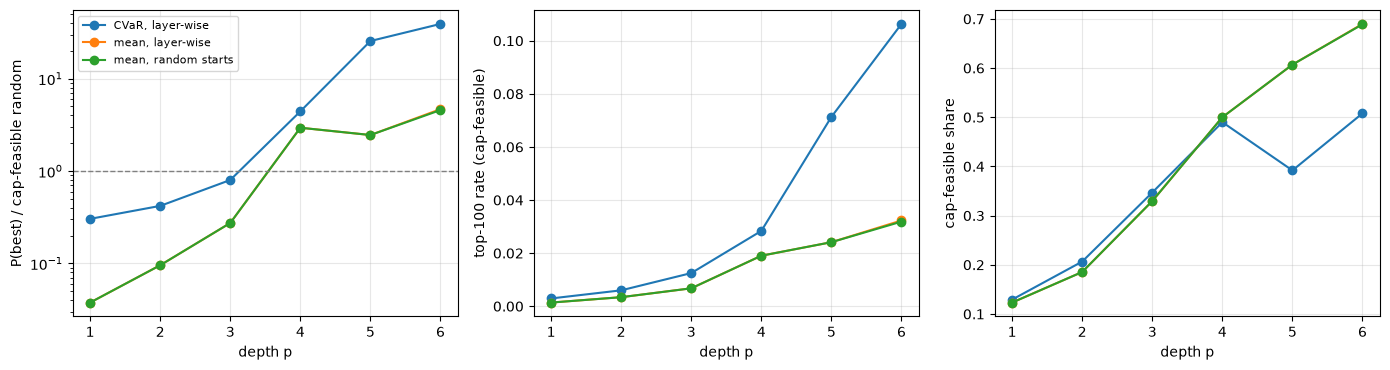

method CVaR, layer-wise mean, layer-wise mean, random starts
p                                                           
1              3.91e-05         4.85e-06            4.85e-06
2              5.39e-05         1.23e-05            1.23e-05
3              1.03e-04         3.52e-05            3.52e-05
4              5.69e-04         3.78e-04            3.78e-04
5              3.28e-03         3.15e-04            3.15e-04
6              5.02e-03         6.01e-04            5.87e-04


In [14]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for name, d in df_scale.groupby("method"):
    ax[0].plot(d.p, d.enh_vs_cap, marker="o", label=name)
    ax[1].plot(d.p, d.top100, marker="o", label=name)
    ax[2].plot(d.p, d.feasible, marker="o", label=name)
ax[0].axhline(1, color="gray", ls="--", lw=1)
ax[0].set_yscale("log"); ax[0].set_ylabel("P(best) / cap-feasible random")
ax[1].set_ylabel("top-100 rate (cap-feasible)"); ax[2].set_ylabel("cap-feasible share")
for a in ax:
    a.set_xlabel("depth p"); a.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print(df_scale.pivot(index="p", columns="method", values="p_best").map(lambda v: f"{v:.2e}").to_string())

### Reading the results

All numbers here are for one instance (n = 20, seed 2026) and one training run per setting.

- **Methods.** CVaR layer-wise has the highest P(best) of the three methods at every depth: 5.69e-04 at p = 4
  (4.4x the cap-feasible baseline) and 5.02e-03 at p = 6 (39.1x). The mean objective reaches 6.01e-04 with
  layer-wise growth and 5.87e-04 with random starts at p = 6 (4.7x and 4.6x). For the mean objective, layer-wise
  growth and the best of 3 random starts give the same P(best) to three significant figures at p = 1-5, so on this
  instance layer-wise growth gave no measurable gain over random starts. The mean objective does reach a better
  average (approximation ratio r = 0.910 vs 0.888 for CVaR at p = 6); CVaR trades average for the low-cost tail.
- **Depth.** The optimizer minimizes the mean or the CVaR, not P(best), so P(best) need not improve with p. In
  this run the depth that maximizes P(best) is p = 6 (the deepest tested) for all three methods, but the curves
  are not monotone: for the mean objective P(best) drops from 3.78e-04 at p = 4 to 3.15e-04 at p = 5 before
  rising at p = 6, and the CVaR cap-feasible share goes 0.490, 0.392, 0.508 at p = 4, 5, 6. We do not headline a
  depth; the verdict depth p = 4 was fixed before any run.
- **Convergence.** CVaR layer-wise at p = 5 and p = 6, and mean with random starts at p = 6, stopped at the
  iteration limit (`STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT`, `MAXITER` = 40). Every other training converged.
  The p = 5 and 6 CVaR numbers could change with more iterations.

### CVaR tail fraction

The main run uses `alpha = 0.2`. We repeat the CVaR layer-wise training at `alpha = 0.01` and `0.05` (smaller
alpha focuses the objective on a thinner low-cost tail).

In [15]:
t = time.time()
res_alpha = {0.2: res_cvar}
for a_ in ALPHAS:
    if a_ not in res_alpha:
        res_alpha[a_] = train_layerwise(sim, PMAX, kind="cvar", alpha=a_, maxiter=MAXITER, return_info=True)
alpha_rows = []
for a_ in ALPHAS:
    for p in range(1, PMAX + 1):
        r_ = res_alpha[a_][p]
        alpha_rows.append(dict(alpha=a_, p=p, **metrics(sim.probs(r_["x"][:p], r_["x"][p:])),
                               nfev=r_["nfev"], nit=r_["nit"], success=r_["success"], message=r_["message"]))
df_alpha = pd.DataFrame(alpha_rows)
print(f"alpha sweep took {time.time() - t:.0f} s")
display(df_alpha[["alpha", "p", "p_best", "feasible", "p_best_cond", "enh_vs_cap", "top10", "r",
                  "nfev", "nit", "success", "message"]])

alpha sweep took 142 s


,alpha,p,p_best,feasible,p_best_cond,enh_vs_cap,top10,r,nfev,nit,success,message
0,0.01,1,0.000045,0.117225,0.000383,0.349216,0.000375,0.744740,72,7,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
1,0.01,2,0.000502,0.128156,0.003918,3.904675,0.004639,0.747551,112,24,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
2,0.01,3,0.001901,0.114276,0.016634,14.780985,0.009512,0.768188,138,21,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
3,0.01,4,0.005532,0.121686,0.045463,43.018557,0.014274,0.778368,171,28,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
4,0.01,5,0.010230,0.147426,0.069389,79.546625,0.022617,0.793701,186,10,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
5,0.01,6,0.010444,0.126644,0.082464,81.209168,0.019170,0.792894,191,2,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
6,0.05,1,0.000043,0.122832,0.000352,0.335984,0.000369,0.735251,72,7,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
7,0.05,2,0.000126,0.177823,0.000711,0.982788,0.000839,0.794778,90,15,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
8,0.05,3,0.000122,0.319769,0.000382,0.950481,0.001326,0.834293,106,14,True,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
9,0.05,4,0.000769,0.434178,0.001771,5.977970,0.003264,0.858116,124,16,True,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


### Penalty strength: data bound vs oracle

The main run uses the data-only bound. Is a smaller penalty easier to train? We train CVaR layer-wise
(`alpha = 0.2`) to p = `P_LAMBDA` at three penalties: the brute-force oracle (reference only, it needs the answer),
the data bound (main), and their geometric midpoint. The optimum among cap-feasible portfolios is the same for all
three, because the penalty is zero on cap-feasible portfolios. The data-bound row reuses the main run (same
recipe, deterministic). If the cap did not bind, the oracle penalty would be 0 with no geometric midpoint, and the
cell would run the data bound only and say so.

In [16]:
t = time.time()
if lam_oracle > 0:
    lam_mid = float(np.sqrt(lam_oracle * lam_s))
    sweep = [("oracle (reference)", lam_oracle), ("geometric midpoint", lam_mid), ("data bound (main)", lam_s)]
else:   # cap does not bind: the oracle penalty is 0 and has no geometric midpoint, so only the data bound is run
    print("cap does not bind on this instance (oracle lambda = 0): sweep reduced to the data bound")
    sweep = [("data bound (main)", lam_s)]
lambda_rows = []
for name, lam in sweep:
    c_ = base + lam * exc
    if name.startswith("data bound"):
        sim_l, r_ = sim, res_cvar[P_LAMBDA]
    else:
        sim_l = SubspaceQAOA(ints, N, c_)
        r_ = train_layerwise(sim_l, P_LAMBDA, kind="cvar", alpha=0.2, maxiter=MAXITER, return_info=True)[P_LAMBDA]
    pr_ = sim_l.probs(r_["x"][:P_LAMBDA], r_["x"][P_LAMBDA:])
    m = metrics(pr_, c_)
    order_ = np.argsort(c_, kind="stable")
    lambda_rows.append(dict(lambda_choice=name, lam=lam, p=P_LAMBDA, p_best=m["p_best"], feasible=m["feasible"],
                            p_best_cond=m["p_best_cond"], enh_vs_cap=m["enh_vs_cap"], top10=m["top10"],
                            violators_in_top10=int((~feas[order_[:10]]).sum()),
                            violators_in_top100=int((~feas[order_[:100]]).sum()),
                            nfev=r_["nfev"], success=r_["success"]))
df_lambda = pd.DataFrame(lambda_rows)
print(f"lambda sweep took {time.time() - t:.0f} s")
display(df_lambda)

lambda sweep took 67 s


,lambda_choice,lam,p,p_best,feasible,p_best_cond,enh_vs_cap,top10,violators_in_top10,violators_in_top100,nfev,success
0,oracle (reference),0.199685,4,0.008602,0.228393,0.037664,66.890821,0.029856,0,23,170,True
1,geometric midpoint,0.532983,4,0.002916,0.397482,0.007337,22.678022,0.011465,0,0,159,True
2,data bound (main),1.422596,4,0.000569,0.490025,0.001161,4.422422,0.003044,0,0,131,True


### Reading the results

Single instance (n = 20, seed 2026), single training per setting; these are the numbers recipe T in Section 6 was
chosen from, so they are tuned on this instance.

- **CVaR tail fraction.** Enhancement over the cap-feasible baseline at p = 4: 43.0x (alpha = 0.01), 6.0x
  (0.05) and 4.4x (0.2, main run); at p = 6: 81.2x, 50.9x and 39.1x. A thinner tail puts more probability on the
  optimum but less on cap-feasible portfolios (cap-feasible share at p = 4: 0.122, 0.434, 0.490). At alpha = 0.01
  every layer converged; at alpha = 0.05 and 0.2 the p = 5 and 6 layers hit the iteration limit.
- **Penalty strength: a smaller penalty trains better, plainly.** CVaR (alpha = 0.2) at p = 4: oracle penalty
  0.1997 gives 66.9x (cap-feasible share 0.228), the geometric midpoint 0.533 gives 22.7x (0.397), and the data
  bound 1.4226 (main run) gives 4.4x (0.490). On this instance the data-only penalty costs about a factor of 15 in
  P(best) against the oracle. The main run stays on the data bound, fixed before any run: the oracle and the
  midpoint are both computed from the brute-force answer, which a real user would not have.

### Barren-plateau check

Variance over random angles of $\partial \langle C \rangle / \partial \gamma_1$ for n = 8, 10, ..., 20 and
p = 1 to 4 (`GV_DRAWS` draws each, central difference). Each size uses its own instance (seed 2026), its own
data-bound penalty, and the cost **rescaled to [0, 1] by its range** in both the phase layer and the observable,
so the trend is not a cost-scale effect. Sizes divisible by 4 use the notebook's rule (family A: sectors of 4, at
most 2 per sector); n = 10, 14, 18 cannot be split into sectors of 4, so they use family B (sectors of 2, at most 1
per sector). **The two families are different problems**: they differ in the cap-feasible fraction and in how much
of the cost range the penalty takes (both columns are in the table), so they are tabulated and plotted as two
separate series. A zig-zag across n that alternates with the family is not a size trend; any claim is limited to
what each series shows on its own. Angles: gamma uniform in [-pi, pi], beta uniform in [0, pi]. These are small
sizes: a flat trend here does not rule out a barren plateau at larger n.

gradient check took 153 s; Var[dE/dgamma_1] with cost scaled to [0, 1]:


,family,cap_feasible_fraction,penalty_share_of_range,var_p1,var_p2,var_p3,var_p4
n,,,,,,,
8,"A: sectors of 4, cap 2",0.514,0.90,2.49e-04,2.06e-04,2.24e-04,1.93e-04
10,"B: sectors of 2, cap 1",0.127,0.71,7.08e-04,3.29e-04,3.12e-04,2.71e-04
12,"A: sectors of 4, cap 2",0.234,0.81,3.93e-04,2.12e-04,2.04e-04,1.52e-04
14,"B: sectors of 2, cap 1",0.037,0.78,2.79e-04,1.36e-04,1.07e-04,8.93e-05
16,"A: sectors of 4, cap 2",0.101,0.91,6.34e-05,2.83e-05,2.24e-05,1.58e-05
18,"B: sectors of 2, cap 1",0.011,0.75,1.42e-04,7.05e-05,5.29e-05,4.84e-05
20,"A: sectors of 4, cap 2",0.042,0.88,8.11e-05,3.54e-05,2.80e-05,1.63e-05


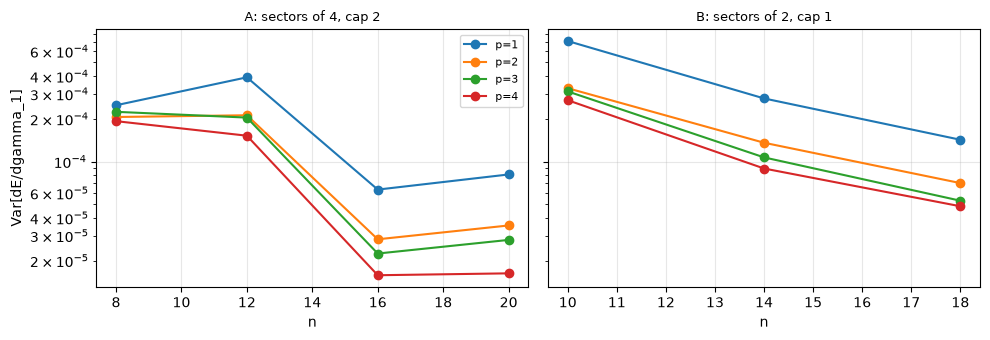

In [17]:
t = time.time()
gv, gv_rows = {}, []
for n_ in range(8, 21, 2):
    family = "A: sectors of 4, cap 2" if n_ % 4 == 0 else "B: sectors of 2, cap 1"
    ns_, cap_ = sector_rule(n_) if n_ % 4 == 0 else (n_ // 2, 1)
    i_ = make_instance(n=n_, K=n_ // 2, seed=SEED, n_sectors=ns_, cap=cap_)
    s_ = feasible_states(n_, n_ // 2); X_ = bits_matrix(s_, n_)
    e_ = sector_excess(X_, i_)
    pen_ = lambda_data_bound(i_) * e_
    c_ = base_cost(X_, i_) + pen_
    rng_c = c_.max() - c_.min()
    c_ = (c_ - c_.min()) / rng_c                                # normalize by the range
    sim_g = SubspaceQAOA(s_, n_, c_)
    row = dict(n=n_, family=family, cap_feasible_fraction=float(np.mean(e_ == 0)),
               penalty_share_of_range=float(pen_.max() / rng_c))
    for p in range(1, 5):
        gv[(n_, p)] = grad_variance(sim_g, p, np.random.default_rng(SEED + p), draws=GV_DRAWS, eps=1e-5)
        row[f"var_p{p}"] = gv[(n_, p)]
    gv_rows.append(row)
df_gv = pd.DataFrame(gv_rows).set_index("n")
print(f"gradient check took {time.time() - t:.0f} s; Var[dE/dgamma_1] with cost scaled to [0, 1]:")
display(df_gv.style.format({c: "{:.2e}" for c in df_gv.columns if c.startswith("var_")}
                           | {"cap_feasible_fraction": "{:.3f}", "penalty_share_of_range": "{:.2f}"}))
fams = sorted(df_gv.family.unique())
fig, axs = plt.subplots(1, len(fams), figsize=(10, 3.5), sharey=True)
for ax, fam in zip(np.atleast_1d(axs), fams):
    d = df_gv[df_gv.family == fam]
    for p in range(1, 5):
        ax.semilogy(d.index, d[f"var_p{p}"], marker="o", label=f"p={p}")
    ax.set_title(fam, fontsize=9); ax.set_xlabel("n"); ax.grid(alpha=.3)
np.atleast_1d(axs)[0].set_ylabel("Var[dE/dgamma_1]"); np.atleast_1d(axs)[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Reading the results

Variance of the gradient with the cost scaled to [0, 1], 200 random angle draws per point, read within each family:

- **Family A** (sectors of 4, cap 2; n = 8, 12, 16, 20). At p = 1: 2.49e-04, 3.93e-04, 6.34e-05, 8.11e-05. At
  p = 4: 1.93e-04, 1.52e-04, 1.58e-05, 1.63e-05. From n = 8 to n = 20 the variance falls by about 3x at p = 1 and
  about 12x at p = 4, but not monotonically: it rises from n = 8 to 12 at p = 1 and 2 and from n = 16 to 20 at every p.
- **Family B** (sectors of 2, cap 1; n = 10, 14, 18). At p = 1: 7.08e-04, 2.79e-04, 1.42e-04; at p = 4: 2.71e-04,
  8.93e-05, 4.84e-05. It falls monotonically with n at every p, by 4.7x to 5.9x from n = 10 to 18.
- At each n the variance is generally lower at larger p.

What this supports: over these sizes the gradient variance shrinks with n in both families. Three or four points
per family cannot tell exponential decay (a barren plateau) from slower decay, and the cap-feasible fraction also
falls with n (0.514 to 0.042 in family A), so size and constraint tightness are mixed. At n = 20 and p = 4 the
variance is still 1.63e-05 (gradient standard deviation about 0.004 on a [0, 1] cost scale). The simulator
gradients here are exact; on hardware each would be a shot-noise estimate. No claim is made beyond n = 20.

In [18]:
final_probs = {}
for p in range(1, PMAX + 1):
    x_ = res_cvar[p]["x"]
    final_probs[p] = sim.probs(x_[:p], x_[p:])
show = metrics(final_probs[P_V])
print(f"CVaR layer-wise at p = {P_V} (verdict depth):", {k: (round(v, 6) if np.isfinite(v) else v) for k, v in show.items()})

CVaR layer-wise at p = 4 (verdict depth): {'p_best': 0.000569, 'p_best_cond': 0.001161, 'top10': 0.003044, 'top100': 0.028374, 'r': 0.868215, 'feasible': 0.490025, 'shots_99': 8096.0, 'enh_vs_cap': 4.422422, 'enh_vs_budget': 105.075737}


## 4. Classical baselines

Greedy build-up plus 1-swap local search, and simulated annealing at fixed budget (swap moves), both on the same
penalized cost. We count cost evaluations. QAOA's currency is different, and its training cost below is a lower
bound. Each training `nfev` is one call that returns the exact objective **and** its exact (adjoint) gradient
over all 184,756 portfolios, which costs about 3 forward simulations (column `forward_sims_equiv` = 3 x nfev; the
63 grid-start evaluations are value-only, so this slightly overstates them). On a QPU there is no adjoint
gradient: each gradient would need about 4p more expectation estimates (parameter shift for 2p angles). Column
`qpu_expectations_parameter_shift` = nfev x (1 + 4p) with p the **final** depth for every layer: it is an **upper
estimate**, because the earlier layers had fewer angles, so the true count is lower. Every expectation estimate also needs many shots. So putting `nfev` next to the classical evaluation counts **understates**
QAOA's real cost. Its answer then needs shots on top. We show both beside the classical evaluation counts, and compare the shots QAOA needs to see
the optimum with the draws a random sampler needs, over budget-feasible portfolios and over **cap-feasible**
portfolios (the headline baseline: a classical sampler can draw 2 stocks per sector directly).

Finally we polish QAOA samples with one `swap_descent` call (1-swap steepest descent to a local minimum). Two
controls: the best of the same number of uniformly random cap-feasible draws followed by the same descent
(like-for-like), and the descent from a single random cap-feasible portfolio.

In [19]:
cf = lambda x: float(base_cost(x[None, :], inst)[0] + lam_s * sector_excess(x[None, :], inst)[0])
c_opt = float(cost[opt])
hit = lambda c: abs(c - c_opt) < 1e-9
xg, ev_g = greedy_swap(cf, N, K)
classical = [dict(method="greedy + 1-swap", cost_evaluations=ev_g, runs=1, success_rate=float(hit(cf(xg))))]
for steps in (500, 2000, 5000):
    hits = [hit(simulated_annealing(cf, N, K, steps, np.random.default_rng(1000 + s))[1]) for s in range(20)]
    classical.append(dict(method=f"simulated annealing, {steps} steps", cost_evaluations=steps + 1, runs=20,
                          success_rate=float(np.mean(hits))))
df_classical = pd.DataFrame(classical)
display(df_classical)

# QAOA in shots: P(best) at the verdict depth and at the depth that maximizes it, vs both random samplers
p_star = int(df_scale[df_scale.method == "CVaR, layer-wise"].set_index("p").p_best.idxmax())
shot_rows = []
for label, p in [(f"QAOA CVaR layer-wise, p={P_V} (verdict depth)", P_V), (f"QAOA CVaR layer-wise, p={p_star} (best p)", p_star)]:
    m = metrics(final_probs[p])
    shot_rows.append(dict(sampler=label, p_best=m["p_best"], cap_feasible_share=m["feasible"],
                          shots_99=m["shots_99"], training_nfev=res_cvar[p]["nfev"],
                          forward_sims_equiv=3 * res_cvar[p]["nfev"],
                          # UPPER estimate: uses the final p for every layer (earlier layers had fewer angles)
                          qpu_expectations_parameter_shift=res_cvar[p]["nfev"] * (1 + 4 * p)))
for label, rb in [("uniform over cap-feasible (headline)", rand_cap), ("uniform over budget-feasible", rand_budget)]:
    shot_rows.append(dict(sampler=label, p_best=rb["p_best"], cap_feasible_share=rb["feasible"],
                          shots_99=rb["shots_99"], training_nfev=0, forward_sims_equiv=0,
                          qpu_expectations_parameter_shift=0))
df_shots = pd.DataFrame(shot_rows)
df_shots["shots_99_vs_cap_random"] = rand_cap["shots_99"] / df_shots.shots_99
display(df_shots)

,method,cost_evaluations,runs,success_rate
0,greedy + 1-swap,556,1,1.00
1,"simulated annealing, 500 steps",501,20,0.35
2,"simulated annealing, 2000 steps",2001,20,0.85
3,"simulated annealing, 5000 steps",5001,20,0.75


,sampler,p_best,cap_feasible_share,shots_99,training_nfev,forward_sims_equiv,qpu_expectations_parameter_shift,shots_99_vs_cap_random
0,"QAOA CVaR layer-wise, p=4 (verdict depth)",0.000569,0.490025,8096.0,131,393,2227,4.422925
1,"QAOA CVaR layer-wise, p=6 (best p)",0.005025,0.507913,915.0,227,681,5675,39.134426
2,uniform over cap-feasible (headline),0.000129,1.000000,35808.0,0,0,0,1.000000
3,uniform over budget-feasible,0.000005,0.042088,850831.0,0,0,0,0.042086


In [20]:
# QAOA samples + one swap_descent call, and the same descent from random cap-feasible starts (control)
pr_v = final_probs[P_V] / final_probs[P_V].sum()
polish_rows = []
for shots in (100, 1000, 10000):
    found_raw, found_pol, evs = [], [], []
    for r in range(20):
        draw = np.random.default_rng(5000 + r).choice(len(cost), shots, p=pr_v)
        ok = draw[feas[draw]]
        pick = int(ok[cost[ok].argmin()]) if len(ok) else int(draw[cost[draw].argmin()])
        x_pol, c_pol, ev = swap_descent(cf, X[pick])
        found_raw.append(pick == opt); found_pol.append(hit(c_pol)); evs.append(ev)
    polish_rows.append(dict(start=f"best of {shots:,} QAOA shots (p={P_V})", runs=20,
                            optimum_before_descent=float(np.mean(found_raw)),
                            optimum_after_descent=float(np.mean(found_pol)), mean_descent_evaluations=float(np.mean(evs))))
# Like-for-like control: best of the same number of uniform random cap-feasible draws, then the same descent
for shots in (100, 1000, 10000):
    found_raw, found_pol, evs = [], [], []
    for r in range(20):
        draw = np.random.default_rng(9000 + r).choice(fidx, shots)
        pick = int(draw[cost[draw].argmin()])
        _, c_pol, ev = swap_descent(cf, X[pick])
        found_raw.append(pick == opt); found_pol.append(hit(c_pol)); evs.append(ev)
    polish_rows.append(dict(start=f"best of {shots:,} uniform random cap-feasible draws (control)", runs=20,
                            optimum_before_descent=float(np.mean(found_raw)),
                            optimum_after_descent=float(np.mean(found_pol)), mean_descent_evaluations=float(np.mean(evs))))
found_pol, evs = [], []
for r in range(20):
    start = int(np.random.default_rng(7000 + r).choice(fidx))
    _, c_pol, ev = swap_descent(cf, X[start])
    found_pol.append(hit(c_pol)); evs.append(ev)
polish_rows.append(dict(start="one uniform random cap-feasible portfolio (control)", runs=20,
                        optimum_before_descent=0.0, optimum_after_descent=float(np.mean(found_pol)),
                        mean_descent_evaluations=float(np.mean(evs))))
df_polish = pd.DataFrame(polish_rows)
display(df_polish)

,start,runs,optimum_before_descent,optimum_after_descent,mean_descent_evaluations
0,best of 100 QAOA shots (p=4),20,0.05,0.65,266.0
1,"best of 1,000 QAOA shots (p=4)",20,0.45,0.85,181.0
2,"best of 10,000 QAOA shots (p=4)",20,1.00,1.00,101.0
3,best of 100 uniform random cap-feasible draws ...,20,0.00,0.50,251.0
4,"best of 1,000 uniform random cap-feasible draw...",20,0.15,0.75,236.0
5,"best of 10,000 uniform random cap-feasible dra...",20,0.70,0.70,101.0
6,one uniform random cap-feasible portfolio (con...,20,0.00,0.50,611.0


### Reading the results

- **Classical methods.** Greedy + 1-swap finds the optimum with 556 cost evaluations. Simulated annealing finds it
  in 7 of 20 runs with 500 steps, 17 of 20 with 2,000 steps and 15 of 20 with 5,000 steps (20 runs each, so these
  rates are rough).
- **QAOA in shots.** At the verdict depth p = 4, QAOA needs 8,096 shots for a 99% chance of seeing the optimum,
  against 35,808 draws for the cap-feasible random sampler (4.4x fewer) and 850,831 for the budget-feasible one.
  At p = 6 it needs 915 shots (39.1x fewer than cap-feasible random).
- **QAOA's training cost comes on top.** p = 4 took 131 objective calls (63 grid values + 68 value-and-gradient;
  about 393 forward-simulation
  equivalents, and at most 2,227 expectation estimates with parameter shift on a QPU, an upper estimate); p = 6
  took 227 (63 + 164; at most 5,675). Each call evaluates the whole 184,756-portfolio state, so one call is not comparable
  to one classical cost evaluation; on a QPU every expectation estimate also needs many shots, so even the
  parameter-shift upper estimate understates QAOA's real cost.
- **The classical step finishes the job.** The best of 100 QAOA shots (p = 4) is the optimum in 1 of 20 runs;
  after one `swap_descent` call it is in 13 of 20 (0.65). With 1,000 shots: 0.45 before and 0.85 after. With
  10,000 shots the optimum is already sampled in all 20 runs. Like-for-like control, the best of the same number of
  uniform random cap-feasible draws then the same descent: 0.50, 0.75 and 0.70 after descent (0.00, 0.15 and 0.70
  before) for 100, 1,000 and 10,000 draws, against 0.65, 0.85 and 1.00 for QAOA. Descent from one random
  cap-feasible portfolio reaches the optimum in 10 of 20 runs with 611 evaluations on average; that control starts
  from a single random portfolio, not the best of the same number of random draws, so that comparison favours QAOA.
  QAOA samples are somewhat better starting points, but greedy alone needs only 556 evaluations and no quantum
  samples.

## 5. Hardware realism (fake IBM backend only)

No QPU time is used. Three questions: where do the two-qubit gates of one QAOA layer at n = 20 come from, does a
SWAP network or an open-chain mixer reduce them, and what does device-like noise do to the answers at n = 12 (the
largest size whose noisy simulation is cheap here)?

**Gate counts block by block.** Each block of the p = 1 circuit is transpiled alone for `FakeSherbrooke`
(heavy-hex, ECR gates), optimization level 3, twice: *synthesis only* (no coupling map, basis cx/rz/sx/x) and
*routed* (backend coupling map). Routed counts are given with Qiskit's free layout and with the 20 logical qubits
pinned (`initial_layout`) to a simple 20-qubit path of the heavy-hex graph, the layout a line SWAP network
assumes. Blocks: Dicke preparation, 1-body cost terms, pair terms (one `PauliEvolutionGate`, or a line SWAP
network of RZZ+SWAP), the 3- and 4-body sector terms, and the XY mixer as a ring or as an open chain (the chain
drops the wrap-around edge; it is hardware-friendly but is **not** the mixer we trained). Total rows are whole
circuits transpiled at once, so they need not equal the sum of the blocks.

**Qiskit's `ElidePermutations` pass is disabled for every transpile in this section** (naive circuits too, so the
counts are like-for-like). At optimization level 3 that pass deletes SWAP gates and relabels the qubits instead,
which would throw away a hand-built SWAP network and leave Sabre to route the bare RZZ set. An earlier version of
this notebook measured the network that way, so its SWAP-network counts were really naive routing counts.

In [21]:
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
backend = FakeSherbrooke()
t = time.time()
path20 = heavy_hex_path(backend, N)
bc_free = block_counts(N, K, terms, ring, backend)
bc_path = block_counts(N, K, terms, ring, backend, layout=path20)
df_blocks = pd.DataFrame({
    "synthesis_2q": {k: v["synthesis_2q"] for k, v in bc_free.items()},
    "routed_2q_free_layout": {k: v["routed_2q"] for k, v in bc_free.items()},
    "routed_2q_heavy_hex_path": {k: v["routed_2q"] for k, v in bc_path.items()},
})
df_blocks["routing_overhead_path"] = df_blocks.routed_2q_heavy_hex_path - df_blocks.synthesis_2q
print(f"block counts on {backend.name} in {time.time() - t:.0f} s; heavy-hex path: {path20}")
display(df_blocks)
hi_terms = {k: v for k, v in weights.items() if k >= 3}
print(f"3+-body Pauli terms (from the sector penalty): {hi_terms}; their block costs "
      f"{df_blocks.loc['cost_3plus_body', 'synthesis_2q']} two-qubit gates before routing, "
      f"{df_blocks.loc['cost_3plus_body', 'routed_2q_heavy_hex_path']} routed on the path")

# Cheaper (explicit CRY/CCRY) vs generic (RYGate.control) Dicke preparation
dicke_rows = []
for label, explicit in [("explicit CRY/CCRY (used)", True), ("generic RYGate.control", False)]:
    qc_d = dicke_circuit(N, K, explicit=explicit)
    syn = _transpile(qc_d, backend, False, None, 7, 3)     # synthesis only, same pass manager as block_counts
    dicke_rows.append(dict(dicke=label, synthesis_2q=int(syn.count_ops().get("cx", 0)),
                           routed_2q_free_layout=transpile_counts(qc_d, backend)["two_qubit_gates"],
                           routed_2q_heavy_hex_path=transpile_counts(qc_d, backend, initial_layout=path20)["two_qubit_gates"]))
df_dicke = pd.DataFrame(dicke_rows)
display(df_dicke)
# ESTIMATE only: product of (1 - median 2q error) over the routed 2q gates. estimated_success transpiles with
# Qiskit's FREE layout; the same estimate with the heavy-hex path layout uses that layout's routed total above.
est20 = estimated_success(naive_p1_circuit(N, K, H, ring, 0.5, 0.3), backend)
est20_path = (1 - est20["median_error"]) ** int(df_blocks.loc["total_naive", "routed_2q_heavy_hex_path"])
print("n=20, p=1 ESTIMATED success probability, free layout:", est20)
print(f"n=20, p=1 ESTIMATED success probability, heavy-hex path layout: {est20_path:.2e} "
      f"({int(df_blocks.loc['total_naive', 'routed_2q_heavy_hex_path'])} routed 2q gates)")

block counts on fake_sherbrooke in 18 s; heavy-hex path: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 17, 30, 29, 28, 27, 26, 16]


,synthesis_2q,routed_2q_free_layout,routed_2q_heavy_hex_path,routing_overhead_path
dicke,1172,2076,2042,870
cost_1body,0,0,0,0
cost_pair_naive,378,691,611,233
cost_pair_swap_network,570,570,570,0
cost_3plus_body,70,99,116,46
mixer_ring,40,40,64,24
mixer_open_chain,38,38,38,0
total_naive,1654,3110,3163,1509
total_swap_network,1842,3030,2833,991
total_swap_network_open_chain,1840,2980,2804,964


3+-body Pauli terms (from the sector penalty): {3: 20, 4: 5}; their block costs 70 two-qubit gates before routing, 116 routed on the path


,dicke,synthesis_2q,routed_2q_free_layout,routed_2q_heavy_hex_path
0,explicit CRY/CCRY (used),1172,2076,2042
1,generic RYGate.control,1172,2342,2435


n=20, p=1 ESTIMATED success probability, free layout: {'gate': 'ecr', 'n_gates': 3110, 'median_error': 0.00778809624800933, 'est_success': 2.7528767362749656e-11}
n=20, p=1 ESTIMATED success probability, heavy-hex path layout: 1.82e-11 (3163 routed 2q gates)


### Reading the results

- **Dicke preparation dominates.** It is 1,172 of the 1,654 two-qubit gates before routing (71%), 2,076 of 3,110
  routed with free layout (67%), and 2,042 of 3,163 on the heavy-hex path (65%). It also carries most of the
  routing overhead on the path (870 of 1,509 extra gates); the pair terms add 233, the 3- and 4-body terms 46 and
  the ring mixer 24.
- **SWAP network: it pays for itself on a line layout, not before routing.** Pair-term block: the network costs 570
  two-qubit gates before routing against 378 for the naive block (+192: the 190 SWAPs, each merged with its RZZ into
  about 3 CX), and it needs **no routing at all** (570 routed with free layout and on the path), while the naive
  block routes to 691 (free) and 611 (path). So the network block is 121 gates (17.5%) cheaper with free layout and
  41 (6.7%) cheaper on the path. Whole p = 1 circuits: 1,842 vs 1,654 before routing (+188), 3,030 vs 3,110 with
  free layout (-80, -2.6%) and **2,833 vs 3,163 on the heavy-hex path (-330, -10.4%)**. The gain is real but
  bounded: Dicke preparation (2,042 gates on the path) is untouched and is 72% of the network circuit's total.
- **Ring vs open chain mixer.** The chain block costs 38 gates against 64 for the ring on the path (the wrap-around
  edge needs routing). Whole SWAP-network circuits: 2,804 with the chain against 2,833 with the ring on the path
  (-29), and 2,980 against 3,030 with free layout (-50). A small extra saving, and the chain is not the mixer we
  trained.
- **Cheaper Dicke.** The explicit CRY/CCRY form leaves the logical count unchanged (1,172 both) but routes better:
  2,076 vs 2,342 with free layout (-266, -11.4%) and 2,042 vs 2,435 on the path (-393, -16.1%).
- **3- and 4-body terms.** The sector penalty gives 20 three-body and 5 four-body Pauli terms (sectors of 4 give
  no 5-body terms). They cost 70 two-qubit gates before routing and 116 on the path: small next to Dicke.
- **n = 20 estimate.** The estimated success probability of the p = 1 circuit (median ECR error 0.0078 over every
  routed gate) is 2.75e-11 with free layout and 1.82e-11 on the path. No hardware run is feasible at n = 20, even
  at p = 1.

### Noise at n = 12

Same recipe at n = 12 (seed 2026, 3 sectors of 4, at most 2 per sector, data-bound penalty): CVaR layer-wise to
p = 2, then the trained circuit is sampled `NOISE_SHOTS` times on `FakeSherbrooke`'s noise model in Aer, without
and with XX dynamical decoupling (Aer density-matrix method: the exact noisy state, sampled; its cost does not
grow with the number of shots). We count valid shots (exactly 6 stocks), cap-feasible shots among them, top-10
hits (the 10 cheapest cap-feasible portfolios) and optimum hits, with 95% Wilson intervals. Reference rows: the
noiseless circuit (exact probabilities) and pure noise (uniform random 12-bit strings: 924 of 4,096 have weight 6;
among those, 216 of 924 are cap-feasible). The cell prints whether the cap binds on this n = 12 instance; if it does not,
this run does not test the sector rule.

**DD here is a simulator artifact.** Aer's noise model from a fake backend has gate errors, readout errors and
thermal relaxation, but no coherent crosstalk or ZZ coupling, which is what dynamical decoupling mainly suppresses
on hardware. Whatever DD does in this simulation is not evidence for or against DD on a QPU.

In [22]:
t = time.time()
n12, K12 = 12, 6
ns12, cap12 = sector_rule(n12)
b12 = make_bundle(n12, SEED, cap12, n_sectors=ns12)
print(f"n=12 seed {SEED}: sector cap binds (unconstrained optimum violates it): {b12['cap_binds']}")
if not b12["cap_binds"]:
    print("NOTE: the cap does not bind on this instance, so this noise run does not test the sector rule")
s12, c12, f12, o12 = b12["ints"], b12["cost"], b12["feas"], b12["opt"]
sim12 = SubspaceQAOA(s12, n12, c12)
x12 = train_layerwise(sim12, 2, kind="cvar", alpha=0.2, maxiter=MAXITER)[2][0]
qc12 = qaoa_circuit(n12, K12, cost_operator(z_terms(b12["inst"], b12["lam"]), n12), ring_edges(n12), x12[:2], x12[2:])
ideal12 = sim12.probs(x12[:2], x12[2:])
# Noiseless checks: exact circuit statevector, then ideal sampled counts decoded exactly like the noisy path
# (int(key, 2) gives bit i = qubit i = stock i)
sv12 = np.abs(circuit_state(qc12)) ** 2
idx12 = {int(v): j for j, v in enumerate(s12)}
qm12 = qc12.copy(); qm12.measure_all()
aer_ideal = AerSimulator(seed_simulator=11)
cnt12 = aer_ideal.run(transpile(qm12, aer_ideal, optimization_level=0), shots=20000).result().get_counts()
dec = np.zeros(len(s12))
for k_, v_ in cnt12.items():
    dec[idx12[int(k_, 2)]] += v_ / 20000      # KeyError would mean a decode/bit-order bug or a budget leak
print(f"noiseless checks: max |circuit statevector - simulator| = {np.abs(sv12[s12] - ideal12).max():.2e}; "
      f"20,000 decoded ideal shots vs simulator: max deviation {np.abs(dec - ideal12).max():.4f}")
assert np.abs(sv12[s12] - ideal12).max() < 1e-6 and np.abs(dec - ideal12).max() < 0.02, "bit-order/decode mismatch"

f_ids = np.where(f12)[0]
top10_set = set(s12[f_ids[np.argsort(c12[f_ids], kind="stable")[:10]]].tolist())
opt_int = int(s12[o12])
feas_ints = set(s12[f12].tolist())

def ci(k, n):
    lo, hi = wilson_interval(k, n)
    return f"[{lo:.4f}, {hi:.4f}]"

noise_rows = [dict(run="noiseless circuit (exact)", shots=np.nan, valid_rate=1.0, valid_ci="",
                   cap_feasible_rate_of_valid=float(ideal12[f12].sum()), cap_feasible_ci="",
                   top10_rate_of_valid=float(ideal12[np.isin(s12, list(top10_set))].sum()), top10_ci="",
                   optimum_rate_of_valid=float(ideal12[o12]), optimum_ci=""),
              dict(run="pure noise (uniform random bitstring)", shots=np.nan, valid_rate=len(s12) / 2 ** n12, valid_ci="",
                   cap_feasible_rate_of_valid=len(feas_ints) / len(s12), cap_feasible_ci="",
                   top10_rate_of_valid=10 / len(s12), top10_ci="", optimum_rate_of_valid=1 / len(s12), optimum_ci="")]
for dd in (False, True):
    counts = noisy_counts(qc12, backend, shots=NOISE_SHOTS, dd=dd, seed=11, method="density_matrix")
    tot = sum(counts.values())
    valid = {int(k_, 2): v_ for k_, v_ in counts.items() if k_.count("1") == K12}
    n_valid = sum(valid.values())
    n_cap = sum(v_ for k_, v_ in valid.items() if k_ in feas_ints)
    n_top = sum(v_ for k_, v_ in valid.items() if k_ in top10_set)
    n_opt = valid.get(opt_int, 0)
    noise_rows.append(dict(run="noisy + XX DD (simulator artifact)" if dd else "noisy, no DD", shots=tot,
                           valid_shots=n_valid, valid_rate=n_valid / tot, valid_ci=ci(n_valid, tot),
                           cap_feasible_shots=n_cap, cap_feasible_rate_of_valid=n_cap / n_valid if n_valid else np.nan,
                           cap_feasible_ci=ci(n_cap, n_valid), top10_shots=n_top,
                           top10_rate_of_valid=n_top / n_valid if n_valid else np.nan, top10_ci=ci(n_top, n_valid),
                           optimum_shots=n_opt, optimum_rate_of_valid=n_opt / n_valid if n_valid else np.nan,
                           optimum_ci=ci(n_opt, n_valid)))
df_noise = pd.DataFrame(noise_rows)
print(f"noisy simulation at n = 12 took {time.time() - t:.0f} s")
display(df_noise)
print("n=12, p=2 ESTIMATED success probability:", estimated_success(qc12, backend))

n=12 seed 2026: sector cap binds (unconstrained optimum violates it): True


noiseless checks: max |circuit statevector - simulator| = 1.01e-16; 20,000 decoded ideal shots vs simulator: max deviation 0.0024


noisy simulation at n = 12 took 119 s


,run,shots,valid_rate,valid_ci,cap_feasible_rate_of_valid,cap_feasible_ci,top10_rate_of_valid,top10_ci,optimum_rate_of_valid,optimum_ci,valid_shots,cap_feasible_shots,top10_shots,optimum_shots
0,noiseless circuit (exact),NaN,1.000000,,0.338643,,0.128947,,0.019837,,NaN,NaN,NaN,NaN
1,pure noise (uniform random bitstring),NaN,0.225586,,0.233766,,0.010823,,0.001082,,NaN,NaN,NaN,NaN
2,"noisy, no DD",8192.0,0.215088,"[0.2063, 0.2241]",0.225880,"[0.2070, 0.2460]",0.010216,"[0.0065, 0.0161]",0.000000,"[0.0000, 0.0022]",1762.0,398.0,18.0,0.0
3,noisy + XX DD (simulator artifact),8192.0,0.223511,"[0.2146, 0.2327]",0.217368,"[0.1991, 0.2368]",0.010923,"[0.0071, 0.0168]",0.001092,"[0.0003, 0.0040]",1831.0,398.0,20.0,2.0


n=12, p=2 ESTIMATED success probability: {'gate': 'ecr', 'n_gates': 1397, 'median_error': 0.00778809624800933, 'est_success': 1.8046499007400566e-05}


### Reading the results

The cap binds on this n = 12 instance, and the noiseless checks pass (circuit vs simulator 1.01e-16; 20,000
decoded ideal shots within 0.0024 of the simulator), so decoding is correct.

- **Valid shots (exactly 6 stocks).** No DD: 21.5% (95% interval 20.6%-22.4%); with DD: 22.4% (21.5%-23.3%);
  pure noise: 22.6% (924 of 4,096); noiseless circuit: 100%. The no-DD interval sits just below the pure-noise
  rate and the DD interval contains it: the budget structure the ideal circuit has is gone.
- **After post-selection on 6 stocks.** Cap-feasible: 22.6% (20.7%-24.6%) without DD and 21.7% (19.9%-23.7%) with
  DD, against 23.4% for pure noise and 33.9% noiseless. Top-10: 1.02% (0.65%-1.61%) and 1.09% (0.71%-1.68%),
  against 1.08% for pure noise and 12.9% noiseless. Optimum: 0 of 1,762 valid shots (0%-0.22%) and 2 of 1,831
  (0.03%-0.40%), against 0.11% for pure noise and 1.98% noiseless. Every interval contains the pure-noise rate and
  excludes the noiseless one: the output is **indistinguishable from pure noise within the error bars**, and
  post-selection cannot recover a signal that is not there.
- **DD.** The DD and no-DD rows overlap within their intervals; in any case DD here is a simulator artifact.
- **Estimate.** The n = 12, p = 2 circuit has 1,397 routed ECR gates and an estimated success probability of
  1.8e-05, consistent with the noise floor seen above. At n = 20 the estimate (Section 5, about 2e-11) says no
  hardware run is feasible.

## 6. Verdict: the largest instance solved well

**Recipe (fixed).** CVaR (`alpha = 0.2`) layer-wise training to p = `P_V` = 4 with `MAXITER` iterations per
layer, data-bound penalty, sectors of 4 with at most 2 per sector, K = n/2, for n = 12, 16 and 20 and eight
instances per size (seeds 2026-2033). The depth p = 4 was fixed before any run.

**Two criteria, both reported.**

- **Fair criterion (headline).** For each n, the **median over seeds** of the enhancement
  P(best) / (1 / number of cap-feasible portfolios) is at least 10. The baseline is a classical sampler that
  draws uniformly among portfolios already obeying the budget and the sector rule, which is trivial to build.
  "Largest instance solved well" = largest n that passes.
- **Original criterion (seed 2026 only, unchanged definition).** With 10^4 shots the best sampled cap-feasible
  portfolio is the optimum or within 1% of the optimal-to-worst penalized cost range, **and** P(best) is at least
  10x the budget-feasible random baseline. The 1% band is measured on the full penalized cost range, as originally defined. Under
  the data-bound lambda that range is at least as wide as under the oracle lambda used originally (cap violators cost
  more), so the band is **looser** here than it was. We therefore also show the gap relative to the cap-feasible
  cost range (`gap_pct_of_cap_feasible_range`, from `run_trial`).

**Disclosure.** The original criterion was written before the first run. After review we changed the headline
baseline from budget-feasible to cap-feasible random sampling (the budget-feasible sampler wastes most draws on
portfolios a classical method would never propose) and moved from one seed to eight per size. The fair criterion
was therefore set after seeing earlier results and is not pre-registered. The sector rule also changed (Section 1).
We also report, for every size, P(find the optimum within 100, 1,000 and 10,000 shots) next to the same number for
the cap-feasible random sampler.

In [23]:
def trial_row(n_, s_, tr, p):
    """One row of the per-seed verdict table, read at depth p of a run_trial result."""
    e = tr["per_p"][str(p)]
    layers = [tr["per_p"][str(q)] for q in range(1, p + 1)]
    row = dict(n=n_, seed=s_, cap_binds=tr["cap_binds"], lam=tr["lam"], n_cap_feasible=tr["n_feas"],
               n_budget_feasible=tr["n_all"], p_best=e["p_best"], cap_feasible_share=e["feasible"],
               p_best_cond=e["p_best_cond"], enh_vs_cap=e["enh_vs_cap"], enh_vs_budget=e["enh_vs_budget"],
               nfev=e["nfev"], success=e["success"],
               layers_hit_maxiter=sum("ITERATIONS REACHED LIMIT" in q["message"].upper() for q in layers),
               layers_not_converged=sum(not q["success"] for q in layers))
    for M in ("100", "1000", "10000"):
        row[f"p_find_{M}"] = e["shots"][M]["p_find"]
        row[f"p_find_{M}_cap_random"] = e["shots"][M]["p_find_cap_random"]
    row["rank_best_of_10000"] = e["shots"]["10000"]["rank"]
    return row


def verdict_table(df):
    """Fair criterion per n: median over seeds of P(best) x |cap-feasible| >= 10."""
    g = df.groupby("n")
    out = pd.DataFrame({
        "seeds": g.size(), "seeds_cap_binds": g.cap_binds.sum(),
        "enh_vs_cap_median": g.enh_vs_cap.median(), "enh_vs_cap_min": g.enh_vs_cap.min(), "enh_vs_cap_max": g.enh_vs_cap.max(),
        "cap_feasible_share_median": g.cap_feasible_share.median(),
        "p_find_100_median": g.p_find_100.median(), "p_find_100_cap_random": g.p_find_100_cap_random.first(),
        "p_find_1000_median": g.p_find_1000.median(), "p_find_1000_cap_random": g.p_find_1000_cap_random.first(),
        "p_find_10000_median": g.p_find_10000.median(), "p_find_10000_cap_random": g.p_find_10000_cap_random.first(),
        "optimizer_success": g.success.sum(),
        "runs_with_a_layer_at_maxiter": g.layers_hit_maxiter.apply(lambda v: int((v > 0).sum())),
    })
    out["solved_well_fair"] = out.enh_vs_cap_median >= 10
    return out


t0 = time.time()
trials, orig_extra = {}, {}
for n_ in (12, 16, 20):
    ns_, cap_ = sector_rule(n_)
    for s_ in SEEDS_V:
        b_ = make_bundle(n_, s_, cap_, n_sectors=ns_)
        trials[(n_, s_)] = run_trial(b_, pmax=P_V, alpha=0.2, maxiter=MAXITER, shots_list=(100, 1000, 10000), seed=s_)
        c_, f_ = b_["cost"], b_["feas"]
        rng_full = float(c_.max() - c_.min())
        frac = float(np.mean(f_ & (c_ <= c_[b_["opt"]] + 0.01 * rng_full)))     # share passing the 1% test
        orig_extra[(n_, s_)] = dict(cost_min=float(c_[b_["opt"]]), range_full=rng_full, frac_within_1pct=frac)
    print(f"n={n_}: {len(SEEDS_V)} trials done ({time.time() - t0:.0f} s)")

df_verdict_seeds = pd.DataFrame([trial_row(n_, s_, tr, P_V) for (n_, s_), tr in trials.items()])
display(df_verdict_seeds)

n=12: 8 trials done (3 s)


n=16: 8 trials done (25 s)


n=20: 8 trials done (269 s)


,n,seed,cap_binds,lam,n_cap_feasible,n_budget_feasible,p_best,cap_feasible_share,p_best_cond,enh_vs_cap,enh_vs_budget,nfev,success,layers_hit_maxiter,layers_not_converged,p_find_100,p_find_100_cap_random,p_find_1000,p_find_1000_cap_random,p_find_10000,p_find_10000_cap_random,rank_best_of_10000
0,12,2026,True,0.699819,216,924,0.120137,0.528380,0.227368,25.949499,111.006192,158,True,0,0,0.999997,0.371260,1.000000,0.990346,1.000000,1.000000,1
1,12,2027,False,0.778674,216,924,0.116291,0.487895,0.238353,25.118854,107.452877,203,False,1,1,0.999996,0.371260,1.000000,0.990346,1.000000,1.000000,1
2,12,2028,True,0.639354,216,924,0.126056,0.497062,0.253603,27.228136,116.475916,187,False,1,1,0.999999,0.371260,1.000000,0.990346,1.000000,1.000000,1
3,12,2029,True,0.752039,216,924,0.019825,0.437896,0.045273,4.282122,18.317968,207,False,1,1,0.864986,0.371260,1.000000,0.990346,1.000000,1.000000,1
4,12,2030,True,0.603319,216,924,0.075149,0.538886,0.139453,16.232223,69.437844,206,False,1,1,0.999595,0.371260,1.000000,0.990346,1.000000,1.000000,1
5,12,2031,True,0.753645,216,924,0.065874,0.744015,0.088539,14.228830,60.867774,207,True,0,0,0.998902,0.371260,1.000000,0.990346,1.000000,1.000000,1
6,12,2032,True,0.641804,216,924,0.117343,0.506822,0.231526,25.345988,108.424504,196,True,1,1,0.999996,0.371260,1.000000,0.990346,1.000000,1.000000,1
7,12,2033,False,0.634012,216,924,0.093878,0.566234,0.165793,20.277603,86.743081,185,True,0,0,0.999948,0.371260,1.000000,0.990346,1.000000,1.000000,1
8,16,2026,True,1.048051,1296,12870,0.002373,0.401487,0.005911,3.075714,30.543546,152,True,0,0,0.211486,0.074286,0.907084,0.537867,1.000000,0.999556,1
9,16,2027,True,1.097724,1296,12870,0.001442,0.594116,0.002428,1.869351,18.563695,144,True,0,0,0.134410,0.074286,0.763886,0.537867,0.999999,0.999556,1


In [24]:
# Fair criterion (headline): median over seeds of P(best) x |cap-feasible| >= 10
df_verdict = verdict_table(df_verdict_seeds)
display(df_verdict)
passed = df_verdict.index[df_verdict.solved_well_fair]
print("largest n solved well under the fair criterion:", int(passed.max()) if len(passed) else "none")

# Original criterion, seed 2026 only (definition unchanged; sampling stream is run_trial's)
orig_rows = []
for n_ in (12, 16, 20):
    e = trials[(n_, 2026)]["per_p"][str(P_V)]
    sh = e["shots"]["10000"]
    ex = orig_extra[(n_, 2026)]
    gap = (sh["best_cost"] - ex["cost_min"]) / ex["range_full"] if sh["best_cost"] is not None else np.inf
    orig_rows.append(dict(n=n_, p_best=e["p_best"], cap_feasible_share=e["feasible"], vs_budget_random=e["enh_vs_budget"],
                          best_of_10000_rank=sh["rank"], best_of_10000_gap_pct_of_full_range=100 * gap,
                          gap_pct_of_cap_feasible_range=sh["gap_pct"],
                          frac_within_1pct=ex["frac_within_1pct"],
                          p_random_10000_passes_1pct=1 - (1 - ex["frac_within_1pct"]) ** 10_000,
                          solved_well_original=bool(e["enh_vs_budget"] >= 10 and (sh["rank"] == 1 or gap <= 0.01))))
df_verdict_orig = pd.DataFrame(orig_rows)
display(df_verdict_orig)
po = df_verdict_orig.n[df_verdict_orig.solved_well_original]
print("largest n solved well under the original criterion (seed 2026):", int(po.max()) if len(po) else "none")

,seeds,seeds_cap_binds,enh_vs_cap_median,enh_vs_cap_min,enh_vs_cap_max,cap_feasible_share_median,p_find_100_median,p_find_100_cap_random,p_find_1000_median,p_find_1000_cap_random,p_find_10000_median,p_find_10000_cap_random,optimizer_success,runs_with_a_layer_at_maxiter,solved_well_fair
n,,,,,,,,,,,,,,,
12,8,6,22.698229,4.282122,27.228136,0.517601,0.999972,0.371260,1.000000,0.990346,1.000000,1.000000,4,5,True
16,8,7,2.399464,0.061650,17.570137,0.468710,0.168467,0.074286,0.829926,0.537867,1.000000,0.999556,4,4,False
20,8,8,0.503559,0.166450,4.449306,0.491786,0.006454,0.012779,0.062572,0.120682,0.469104,0.723651,8,0,False


largest n solved well under the fair criterion: 12


,n,p_best,cap_feasible_share,vs_budget_random,best_of_10000_rank,best_of_10000_gap_pct_of_full_range,gap_pct_of_cap_feasible_range,frac_within_1pct,p_random_10000_passes_1pct,solved_well_original
0,12,0.120137,0.528380,111.006192,1,0.0,0.0,0.002165,1.000000,True
1,16,0.002373,0.401487,30.543546,1,0.0,0.0,0.001088,0.999981,True
2,20,0.000569,0.490025,105.075737,1,0.0,0.0,0.000103,0.642434,True


largest n solved well under the original criterion (seed 2026): 20


### Held-out test of a tuned recipe (recipe T)

The sensitivity sweeps of Section 3 (alpha and lambda, on the seed-2026 instance at n = 20 only) suggest settings
that do better than the pre-committed recipe on that one instance. A setting picked by looking at one instance can
simply be fitted to it, so we test it on instances it has not seen.

**Recipe T (fixed before this run, never changed after):** CVaR `alpha = ALPHA_T` = 0.01, layer-wise training to
p = `P_T` = 6, `MAXITER` iterations per layer, **data-bound** penalty (the oracle penalty is excluded: it needs the
answer). It was **chosen by looking at seed 2026 only**, so it is evaluated on the **held-out seeds 2027-2033**
(`SEEDS_T`) at n = 12, 16 and 20, with the same fair metric and the same "solved well" rule (median enhancement
over the cap-feasible random baseline >= 10). The pre-committed recipe's numbers are shown on the same held-out
seeds for a like-for-like comparison. **Recipe T is not the pre-committed recipe**: the headline verdict above stays
defined by the pre-committed recipe over all eight seeds; recipe T is a sensitivity result.

**Timing, disclosed.** We added this test after seeing the pre-committed results on all eight seeds; recipe T's
settings were taken from the seed-2026 sweeps only.

In [25]:
t0 = time.time()
trials_T = {}
for n_ in (12, 16, 20):
    ns_, cap_ = sector_rule(n_)
    for s_ in SEEDS_T:
        b_ = make_bundle(n_, s_, cap_, n_sectors=ns_)
        trials_T[(n_, s_)] = run_trial(b_, pmax=P_T, alpha=ALPHA_T, maxiter=MAXITER, shots_list=(100, 1000, 10000), seed=s_)
    print(f"recipe T, n={n_}: {len(SEEDS_T)} held-out trials done ({time.time() - t0:.0f} s)")
df_verdict_tuned_seeds = pd.DataFrame([trial_row(n_, s_, tr, P_T) for (n_, s_), tr in trials_T.items()])

held_pre = df_verdict_seeds[df_verdict_seeds.seed.isin(SEEDS_T)]
print("held-out seeds in both tables:", sorted(set(held_pre.seed) & set(df_verdict_tuned_seeds.seed)))
LABEL_PRE = f"pre-committed (alpha 0.2, p {P_V}), held-out seeds"
LABEL_T = f"recipe T (alpha {ALPHA_T}, p {P_T}; chosen on seed 2026; held-out seeds; not pre-committed)"
df_verdict_tuned = pd.concat({LABEL_PRE: verdict_table(held_pre), LABEL_T: verdict_table(df_verdict_tuned_seeds)},
                             names=["recipe", "n"])
display(df_verdict_tuned)
for lab in (LABEL_PRE, LABEL_T):
    ok_ = df_verdict_tuned.loc[lab]
    ok_ = ok_.index[ok_.solved_well_fair]
    print(f"{lab}: largest n solved well (median >= 10):", int(ok_.max()) if len(ok_) else "none")
# Per seed, side by side
cmp = df_verdict_tuned_seeds.set_index(["n", "seed"])[["enh_vs_cap", "cap_feasible_share", "nfev", "layers_hit_maxiter"]]
cmp = cmp.join(held_pre.set_index(["n", "seed"])[["enh_vs_cap", "cap_feasible_share", "nfev"]], rsuffix="_pre")
cmp["T_over_pre"] = cmp.enh_vs_cap / cmp.enh_vs_cap_pre
display(cmp)

recipe T, n=12: 7 held-out trials done (0 s)


recipe T, n=16: 7 held-out trials done (20 s)


recipe T, n=20: 7 held-out trials done (804 s)
held-out seeds in both tables: [2027, 2028, 2029, 2030, 2031, 2032, 2033]


seeds  seeds_cap_binds  enh_vs_cap_median  enh_vs_cap_min  enh_vs_cap_max  cap_feasible_share_median  p_find_100_median  p_find_100_cap_random  p_find_1000_median  p_find_1000_cap_random  \
recipe                                             n                                                                                                                                                                                                
pre-committed (alpha 0.2, p 4), held-out seeds     12      7                5          20.277603        4.282122       27.228136                   0.506822           0.999948               0.371260            1.000000                0.990346   
                                                   16      7                6           1.869351        0.061650       17.570137                   0.481018           0.134410               0.074286            0.763886                0.537867   
                                                   20      7                7           0.371228        0.166450        4.449306                   0.493548           0.004763               0.012779            0.046620                0.120682   
recipe T (alpha 0.01, p 6; chosen on seed 2026;... 12      7                5           3.611873        2.407320        6.670549                   0.468881           0.814797               0.371260            1.000000                0.990346   
                                                   16      7                6          13.085048        0.296066       21.984525                   0.241063           0.637518               0.074286            0.999961                0.537867   
                                                   20      7                7          30.166682        3.360402      113.233432                   0.185150           0.322063               0.012779            0.979493                0.120682   

                                                       p_find_10000_median  p_find_10000_cap_random  optimizer_success  runs_with_a_layer_at_maxiter  solved_well_fair  
recipe                                             n                                                                                                                    
pre-committed (alpha 0.2, p 4), held-out seeds     12             1.000000                 1.000000                  3                             5              True  
                                                   16             0.999999                 0.999556                  3                             4             False  
                                                   20             0.379614                 0.723651                  7                             0             False  
recipe T (alpha 0.01, p 6; chosen on seed 2026;... 12             1.000000                 1.000000                  7                             0             False  
                                                   16             1.000000                 0.999556                  6                             3              True  
                                                   20             1.000000                 0.723651                  4                             4              True

pre-committed (alpha 0.2, p 4), held-out seeds: largest n solved well (median >= 10): 12
recipe T (alpha 0.01, p 6; chosen on seed 2026; held-out seeds; not pre-committed): largest n solved well (median >= 10): 20


enh_vs_cap  cap_feasible_share  nfev  layers_hit_maxiter  enh_vs_cap_pre  cap_feasible_share_pre  nfev_pre  T_over_pre
n  seed                                                                                                                        
12 2027    6.670549            0.442854   132                   0       25.118854                0.487895       203    0.265559
   2028    6.053872            0.536281    71                   0       27.228136                0.497062       187    0.222339
   2029    3.202115            0.293044   104                   0        4.282122                0.437896       207    0.747787
   2030    3.611873            0.513821    71                   0       16.232223                0.538886       206    0.222513
   2031    2.407320            0.243931    88                   0       14.228830                0.744015       207    0.169186
   2032    2.971586            0.468881   100                   0       25.345988                0.506822       196    0.117241
   2033    6.286581            0.630021    74                   0       20.277603                0.566234       185    0.310026
16 2027    2.731978            0.139494   327                   2        1.869351                0.594116       144    1.461458
   2028   13.085048            0.504473   222                   0        1.582926                0.374655       154    8.266368
   2029    0.296066            0.241063   238                   0        0.061650                0.481018       182    4.802379
   2030   13.793217            0.127419   209                   1        2.929577                0.552853       168    4.708262
   2031    7.792911            0.284669   346                   1        1.635672                0.619927       178    4.764350
   2032   21.984525            0.334972   105                   0       17.570137                0.383462       156    1.251244
   2033   19.261462            0.161427    96                   0       14.591022                0.456401       193    1.320090
20 2027   82.458535            0.111214   161                   0        2.014095                0.493548       133   40.940735
   2028   12.823999            0.149458   261                   2        4.449306                0.447052       132    2.882247
   2029  113.233432            0.185150   186                   0        0.635889                0.479791       134  178.070954
   2030    3.360402            0.410334   237                   0        0.212252                0.499866       128   15.832163
   2031   36.540630            0.117027   333                   1        0.166450                0.460915       137  219.528955
   2032   28.179267            0.204736   285                   2        0.371228                0.531950       125   75.908288
   2033   30.166682            0.291667   268                   1        0.292670                0.518693       149  103.073899

### Reading the results

**Pre-committed recipe, all 8 seeds (the headline verdict).** Median enhancement over the cap-feasible random
baseline: **22.7x at n = 12** (min 4.28x, max 27.2x), **2.40x at n = 16** (0.062x to 17.6x) and **0.50x at n = 20**
(0.166x to 4.45x). The median falls 9.5x from n = 12 to 16 and 4.8x from n = 16 to 20. **Largest n solved well under the fair
criterion: n = 12.** At n = 20 no seed reaches 10x and 5 of 8 seeds are below 1x. Median P(find the optimum within
100 / 1,000 / 10,000 shots): n = 12 0.99997 / 1.0 / 1.0 vs 0.371 / 0.990 / 1.0 for cap-feasible random; n = 16
0.168 / 0.830 / 1.000 vs 0.074 / 0.538 / 0.9996; n = 20 0.0065 / 0.063 / 0.469 vs 0.0128 / 0.121 / 0.724, so at
n = 20 the median QAOA run is worse than the classical sampler at every shot budget. Median cap-feasible share
0.518, 0.469, 0.492.

**Instance caveats.** One instance per seed, 8 seeds per size. The cap binds on 6 of 8 seeds at n = 12 (not on
2027 and 2033), 7 of 8 at n = 16 (not on 2033) and 8 of 8 at n = 20. The final (p = 4) layer converged in 4 of 8
runs at n = 12, 4 of 8 at n = 16 and 8 of 8 at n = 20; some layer stopped at the iteration limit for n = 12 seeds
2027, 2028, 2029, 2030 and 2032, and n = 16 seeds 2029, 2030, 2031 and 2033 (two layers); none at n = 20.

**Held-out tuned recipe T (alpha = 0.01, p = 6; chosen on seed 2026; seeds 2027-2033; not pre-committed).**
Median enhancement: **3.61x at n = 12** (2.41x to 6.67x), **13.1x at n = 16** (0.296x to 22.0x), **30.2x at
n = 20** (3.36x to 113x). By the same rule it passes at n = 16 and 20 and fails at n = 12. On the same held-out
seeds the pre-committed recipe gives 20.3x, 1.87x and 0.37x. Seed by seed, recipe T is better on all 7 seeds at
n = 16 (1.25x to 8.3x better) and at n = 20 (2.9x to 220x better), and worse on all 7 seeds at n = 12 (0.12x to
0.75x of the pre-committed value). Median P(find within 100 / 1,000 / 10,000 shots) at n = 20: 0.322 / 0.979 /
1.000, against 0.0128 / 0.121 / 0.724 for cap-feasible random. The costs: a lower cap-feasible share (median
0.469, 0.241, 0.185 against 0.507, 0.481, 0.494 on the same seeds), more evaluations at n = 20 (161-333 against
125-149), and the iteration limit was hit in some layer for n = 16 seeds 2027 (two layers), 2030 and 2031 and
n = 20 seeds 2028 (two), 2031, 2032 (two) and 2033; the final layer converged in 7, 6 and 4 of 7 runs.

What this shows: the setting tuned on the n = 20 seed-2026 instance transferred to other n = 20 instances and to
n = 16, but not to n = 12. This suggests the pre-committed recipe's failure at n = 16 and 20 depends strongly on
alpha and depth (recipe T also uses p = 6 and more evaluations). We added this test after seeing the pre-committed
results on all eight seeds; recipe T's settings were taken from the seed-2026 sweeps only, so a pre-registered
confirmation would need new seeds. Even with recipe T, greedy search solves every one of
these instances with a few hundred evaluations.

**Original criterion (seed 2026, unchanged definition) and the earlier verdict.** It still passes at all three
sizes: P(best) is 111x, 30.5x and 105x the budget-feasible random baseline, and the best of 10^4 samples is the
exact optimum at n = 12, 16 and 20. It is a weak test. The 1% band is so wide that 10^4 uniform budget-feasible
draws pass it with probability 1.000 at n = 12, 0.99998 at n = 16 and 0.642 at n = 20. At n = 20, 10^4 shots
exceed the 7,776 cap-feasible portfolios: a uniform cap-feasible sampler sees the exact optimum within 10^4 draws
with probability 0.724. The budget-feasible baseline also counts draws that break the sector rule. The earlier
version of this notebook reported "largest instance solved well = 20" from this criterion, with a different sector
rule (4 sectors of 5, at most 3), a penalty derived from the brute-force answer, and one seed. **That conclusion
no longer stands:** with the fair baseline, the data-only penalty and 8 seeds, the pre-committed recipe solves
n = 12 only. The earlier numbers are not comparable and are not reused.

### The answer itself: which stocks does QAOA pick?

Using the n = 20, seed 2026, p = `P_V` CVaR layer-wise state from Section 3, we sample, keep the draws that obey
the sector cap, and take the cheapest. The pick is **re-scored from `mu` and `sigma` regenerated with the README
code** (not from the module's cost arrays) and compared with the brute-force optimum, at 10^4 shots (the verdict
budget) and 10^5 shots.

In [26]:
rng_readme = np.random.default_rng(2026)          # README generator, verbatim, at n = 20
mu_r = rng_readme.uniform(0.05, 0.25, 20)
A_r = rng_readme.normal(0, 0.1, (20, 20))
sigma_r = A_r @ A_r.T
q_r = 0.5
assert np.allclose(mu_r, inst["mu"]) and np.allclose(sigma_r, inst["sigma"])
score = lambda st: float(q_r * sigma_r[np.ix_(st, st)].sum() - mu_r[st].sum())
sector_r = np.arange(20) // 4                        # contiguous sectors of 4
fsorted = np.sort(cost[feas])
sel_rows = []
for shots in (10_000, 100_000):
    pr = final_probs[P_V]
    draw = np.random.default_rng(SEED).choice(len(cost), shots, p=pr / pr.sum())
    ok = draw[feas[draw]]
    if len(ok) == 0:
        sel_rows.append(dict(shots=shots, cap_feasible_shots=0, stocks=None, per_sector=None,
                             risk_adjusted_cost_readme=np.nan, rank_among_cap_feasible=None, is_exact_optimum=False))
        continue
    pick = int(ok[cost[ok].argmin()])
    st = np.where(X[pick])[0]
    sel_rows.append(dict(shots=shots, cap_feasible_shots=len(ok), stocks=st.tolist(),
                         per_sector=np.bincount(sector_r[st], minlength=5).tolist(),
                         risk_adjusted_cost_readme=round(score(st), 5),
                         rank_among_cap_feasible=int((fsorted < cost[pick] - 1e-12).sum()) + 1,
                         is_exact_optimum=bool(pick == opt)))
df_select = pd.DataFrame(sel_rows)
print("exact optimum:", opt_stocks.tolist(), "per sector", np.bincount(sector_r[opt_stocks], minlength=5).tolist(),
      "risk-adjusted cost (README data)", round(score(opt_stocks), 5))
display(df_select)

exact optimum: [1, 3, 4, 6, 10, 11, 12, 15, 17, 19] per sector [2, 2, 2, 2, 2] risk-adjusted cost (README data) -1.11174


,shots,cap_feasible_shots,stocks,per_sector,risk_adjusted_cost_readme,rank_among_cap_feasible,is_exact_optimum
0,10000,4934,"[1, 3, 4, 6, 10, 11, 12, 15, 17, 19]","[2, 2, 2, 2, 2]",-1.11174,1,True
1,100000,48938,"[1, 3, 4, 6, 10, 11, 12, 15, 17, 19]","[2, 2, 2, 2, 2]",-1.11174,1,True


### How we know the answer is good

- **Ground truth is brute force.** Every size is enumerated completely (924, 12,870 and 184,756 budget-feasible
  portfolios), so "found the optimum", ranks and P(best) are checks against the true optimum, not estimates.
- **The pick is re-scored independently.** At n = 20, seed 2026, p = 4: 4,934 of 10,000 samples obey the sector
  rule, and the cheapest of them is the exact optimum, stocks [1, 3, 4, 6, 10, 11, 12, 15, 17, 19] with 2 per
  sector and risk-adjusted cost -1.11174 recomputed from `mu` and `sigma` regenerated with the README code. With
  100,000 samples (48,938 cap-feasible) the pick is the same.
- **Criteria.** The fair criterion passes at n = 12 only for the pre-committed recipe; the held-out recipe T passes
  at n = 16 and 20; the original criterion passes at all sizes on seed 2026 but is weak (see above).
- **Classical methods do it with less.** Greedy + 1-swap (556 evaluations), simulated annealing and random-start
  descent find the same optimum (Section 4) without any quantum samples.
- **Limits.** The fast simulator is checked against the full circuit at n = 12 and 16 only; no QPU was used; the
  hardware estimate in Section 5 rules out a meaningful n = 20 run on current devices.